In [1]:
from hashlib import sha256
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

# Paths relative to the repository root (works when started from the root or from notebook/).
ROOT = Path.cwd() if (Path.cwd() / "data" / "mbc_base.csv").is_file() else Path.cwd().parent
INPUT = ROOT / "data" / "mbc_base.csv"
if not INPUT.is_file():
    raise FileNotFoundError(f"CSV not found: {INPUT}")
OUTPUT_DIR = ROOT / "results"
OUTPUT_DIR.mkdir(exist_ok=True)

COUNTRIES = ("UKR", "IND", "USA", "SAU")
YEARS = (2015, 2019, 2021, 2022)
FOCUS = "METAL"
FINAL = ["HH", "NPISH", "GOV", "GFCF", "INVNT", "DPABR"]

# Кожна галузь має рівно одну групу для підсумовування.
MAPPING = [
    ("COAL",   "B05",           "coal_and_refined_products"),
    ("OILGAS", "B06",           "oil_and_gas"),
    ("ORES",   "B07",           "metal_ores"),
    ("COKE",   "C19",           "coal_and_refined_products"),
    ("METAL",  "C24A",          "own_sector"),
    ("FABMET", "C25",           "fabricated_metals"),
    ("ELEC",   "D",             "electricity_gas_steam"),
    ("WASTE",  "E",             "water_and_waste_services"),
    ("CONSTR", "F",             "construction"),
    ("TRADE",  "G",             "trade"),
    ("TRANSP", "H49+H50+H51",   "transport_and_warehousing"),
    ("WAREH",  "H52",           "transport_and_warehousing"),
    ("OTHERS", "Residual in supplied CSV", "other_industries"),
]
mapping = pd.DataFrame(MAPPING, columns=["sector", "oecd_icio_code", "component"])
sector_group = mapping.set_index("sector")["component"]
sectors = list(sector_group.index)
common_sectors = [sector for sector in sectors if sector != "OTHERS"]
aux_rows = ["TOTAL_IC", "IMP_IC", "TLS", "VA", "OUTPUT"]
value_columns = sectors + ["TOTAL_IC", *FINAL, "OUTPUT", "EXPORT", "IMPORT"]


# Первинні коди, які разом утворюють залишкову групу OTHERS.
other_icio_codes = (
    "A01 A02 A03 B08 B09 C10T12 C13T15 C16 C17_18 C20 C21 C22 C23 C24B "
    "C26 C27 C28 C29 C301 C302T309 C31T33 H53 I J58T60 J61 J62_63 K L M N O P Q R S T"
).split()
mapped_icio_codes = {
    sector: code.split("+") for sector, code, _ in MAPPING if sector != "OTHERS"
}
mapped_icio_codes["OTHERS"] = other_icio_codes
all_icio_codes = [code for sector in sectors for code in mapped_icio_codes[sector]]
if len(all_icio_codes) != 50 or len(set(all_icio_codes)) != 50:
    raise ValueError("The sector mapping must contain 50 distinct OECD ICIO codes.")
mapping["source_industry_count"] = mapping["sector"].map(lambda s: len(mapped_icio_codes[s]))
mapping["source_icio_members"] = mapping["sector"].map(lambda s: "+".join(mapped_icio_codes[s]))

keys = ["country", "year", "row"]
row_layout = {**dict.fromkeys(sectors, "industry"), "TOTAL_IC": "total",
              **dict.fromkeys(aux_rows[1:], "input")}
required = keys + ["row_name", "row_type", "block_status", "block_note"] + value_columns
raw = pd.read_csv(INPUT, encoding="utf-8-sig", dtype={"year": "Int64"})
if missing := set(required).difference(raw.columns):
    raise ValueError(f"Missing CSV columns: {sorted(missing)}")
if raw[keys].isna().any().any():
    raise ValueError("Missing country, year or row code.")
if raw.duplicated(keys).any():
    duplicates = raw.loc[raw.duplicated(keys, keep=False), keys]
    raise ValueError("Duplicate country-year-row keys:\n" + duplicates.to_string(index=False))
raw[value_columns] = raw[value_columns].apply(pd.to_numeric, errors="raise")
if np.isinf(raw[value_columns].to_numpy(dtype=float)).any():
    raise ValueError("Infinite values in CSV.")
for col in ("row_name", "block_status", "block_note"):
    if raw[col].isna().any() or raw[col].astype(str).str.strip().eq("").any():
        raise ValueError(f"Missing row metadata in {col}.")
if not raw["block_status"].eq("ok").all():
    raise ValueError("Review blocks with a status other than 'ok'.")

expected = {(c, y) for c in COUNTRIES for y in YEARS}
blocks = {(country, int(year)): table.set_index("row")
          for (country, year), table in raw.groupby(["country", "year"], sort=False)}
if set(blocks) != expected:
    raise ValueError(f"Unexpected country-year coverage: {sorted(set(blocks) ^ expected)}")
if raw.groupby("row")["row_name"].nunique().gt(1).any():
    raise ValueError("Inconsistent industry or accounting row labels across blocks.")

for key, block in blocks.items():
    if set(block.index) != set(row_layout):
        raise ValueError(f"{key}: different row coverage: {sorted(set(block.index) ^ set(row_layout))}")
    expected_types = pd.Series(row_layout).reindex(block.index)
    if not block["row_type"].eq(expected_types).all():
        raise ValueError(f"{key}: incorrect industry or accounting row type.")
    if block["block_note"].nunique() != 1:
        raise ValueError(f"{key}: inconsistent source notes within the block.")

    expected_values = pd.DataFrame(False, index=block.index, columns=value_columns)
    expected_values.loc[sectors, :] = True
    expected_values.loc[aux_rows, sectors] = True
    expected_values.loc["TOTAL_IC", "TOTAL_IC"] = True
    valid_cells = block[value_columns].notna().eq(expected_values)
    if not valid_cells.to_numpy().all():
        invalid = valid_cells.stack()
        cells_with_errors = invalid.index[~invalid].tolist()
        raise ValueError(f"{key}: missing required values or unexpected nonblank cells: {cells_with_errors}")

    if block.loc[sectors, sectors].lt(0).any().any():
        raise ValueError(f"{key}: negative domestic intermediate flows.")
    x = block.loc["OUTPUT", sectors].astype(float)
    if x.lt(0).any() or x.loc[FOCUS] <= 0:
        raise ValueError(f"{key}: negative output or zero output of {FOCUS}.")

mapping["csv_label"] = blocks["UKR", 2022].loc[sectors, "row_name"].to_numpy()
source_metadata = pd.DataFrame([{
    "source_file": INPUT.name, "sha256": sha256(INPUT.read_bytes()).hexdigest(),
    "row_count": len(raw), "block_count": len(blocks), "sector_group_count": len(sectors),
    "python_version": sys.version.split()[0], "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
}])

In [2]:
BALANCE_REL_TOL = 0.00005
TOTAL_ABS_TOL = 0.002


def ratio(numerator, denominator):
    return numerator / denominator.where(denominator.gt(0))


balance_frames = []
audit_rows = []
prepared_blocks = {}
for (country, year), block in blocks.items():
    z = block.loc[sectors, sectors]
    industry = block.loc[sectors]
    x = block.loc["OUTPUT", sectors].astype(float)
    imports_ic = block.loc["IMP_IC", sectors].astype(float)
    taxes = block.loc["TLS", sectors].astype(float)
    va = block.loc["VA", sectors].astype(float)
    domestic_final = industry[FINAL].sum(axis=1)
    sales_gap = x - z.sum(axis=1) - domestic_final - industry["EXPORT"]
    cost_gap = x - z.sum(axis=0) - imports_ic - taxes - va

    own_output_gap = x - industry["OUTPUT"]
    row_total_gap = industry["TOTAL_IC"] - z.sum(axis=1)
    col_total_gap = block.loc["TOTAL_IC", sectors].astype(float) - z.sum(axis=0)
    grand_total_gap = float(block.loc["TOTAL_IC", "TOTAL_IC"]) - z.to_numpy().sum()
    zero_output = x.eq(0)
    inactive_flow = zero_output & (z.abs().sum(axis=1).gt(TOTAL_ABS_TOL)
                                  | z.abs().sum(axis=0).gt(TOTAL_ABS_TOL))
    sales_relative = ratio(sales_gap, x)
    cost_relative = ratio(cost_gap, x)
    threshold = (BALANCE_REL_TOL * x).where(~zero_output, TOTAL_ABS_TOL)
    sector_ok = (
        own_output_gap.abs().le(TOTAL_ABS_TOL)
        & row_total_gap.abs().le(TOTAL_ABS_TOL)
        & col_total_gap.abs().le(TOTAL_ABS_TOL)
        & sales_gap.abs().le(threshold)
        & cost_gap.abs().le(threshold)
        & ~inactive_flow
    )
    block_ok = bool(sector_ok.all() and abs(grand_total_gap) <= TOTAL_ABS_TOL)
    prepared_blocks[country, year] = {
        "Z": z, "industry": industry, "x": x, "imported_inputs": imports_ic,
        "taxes": taxes, "va": va, "domestic_final": domestic_final, "sales_gap": sales_gap,
    }
    balance_frames.append(pd.DataFrame({
        "country": country, "year": year, "sector": sectors, "gross_output": x,
        "row_vs_column_output_gap": own_output_gap,
        "domestic_intermediate_sales_gap": row_total_gap,
        "domestic_intermediate_inputs_gap": col_total_gap,
        "domestic_final_use_missing_count": industry[FINAL].isna().sum(axis=1),
        "reported_gross_exports": industry["EXPORT"], "reported_gross_imports": industry["IMPORT"],
        "sales_residual": sales_gap, "sales_residual_share_of_output": sales_relative,
        "observed_imported_intermediate_inputs": imports_ic,
        "observed_taxes_less_subsidies": taxes, "observed_value_added": va,
        "cost_residual": cost_gap, "cost_residual_share_of_output": cost_relative,
        "zero_output_with_nonzero_domestic_flows": inactive_flow, "sector_passed": sector_ok,
    }))
    audit_rows.append({
        "country": country, "year": year, "missing_output_in": ", ".join(x[x.isna()].index),
        "zero_output_in": ", ".join(x[zero_output].index), "observed_va_count": va.notna().sum(),
        "observed_imported_intermediate_count": imports_ic.notna().sum(),
        "observed_taxes_count": taxes.notna().sum(),
        "sectors_with_missing_domestic_final_use": industry[FINAL].isna().any(axis=1).sum(),
        "max_abs_sales_residual_share_among_observed": sales_relative.abs().max(),
        "max_abs_cost_residual_share_among_observed": cost_relative.abs().max(),
        "max_abs_reported_intermediate_column_gap": col_total_gap.abs().max(),
        "max_abs_reported_intermediate_row_gap": row_total_gap.abs().max(),
        "grand_total_intermediate_gap": grand_total_gap, "block_passed": block_ok,
        "sectors_failed": ", ".join(sector_ok.index[~sector_ok]),
        "source_note": block["block_note"].iloc[0],
    })

audit = pd.DataFrame(audit_rows).sort_values(["year", "country"], ignore_index=True)
balance = pd.concat(balance_frames, ignore_index=True)
preparation_exports = {
    "source_metadata": source_metadata, "sector_mapping": mapping,
    "block_audit": audit, "balance_audit_by_industry": balance,
}
for name, frame in preparation_exports.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

summary = audit[["country", "year", "zero_output_in", "block_passed"]].copy()
summary["max_sales_gap_pct"] = (100 * audit["max_abs_sales_residual_share_among_observed"]).round(6)
summary["max_cost_gap_pct"] = (100 * audit["max_abs_cost_residual_share_among_observed"]).round(6)
display(source_metadata)
display(summary)
if not audit["block_passed"].all():
    failed = audit.loc[~audit["block_passed"], ["country", "year", "sectors_failed"]]
    raise ValueError("Balance check failed. Details: block_audit.csv and balance_audit_by_industry.csv.\n"
                     + failed.to_string(index=False))
print(f"Passed: {len(audit)} country-year blocks, {len(balance)} country-year-sector checks.")

,source_file,sha256,row_count,block_count,sector_group_count,python_version,numpy_version,pandas_version
0,mbc_base.csv,7413e749a8a0b337f9540180bcfc739c63c8d48194d8f3...,288,16,13,3.13.18,2.5.3,3.0.5


,country,year,zero_output_in,block_passed,max_sales_gap_pct,max_cost_gap_pct
0,IND,2015,,True,0.000479,0.000066
1,SAU,2015,COAL,True,0.000941,0.000750
2,UKR,2015,,True,0.004076,0.002784
3,USA,2015,,True,0.000331,0.000040
4,IND,2019,,True,0.000341,0.000040
5,SAU,2019,COAL,True,0.000824,0.000729
6,UKR,2019,,True,0.002942,0.001552
7,USA,2019,,True,0.000339,0.000030
8,IND,2021,,True,0.000069,0.000040
9,SAU,2021,COAL,True,0.000717,0.000564


Passed: 16 country-year blocks, 208 country-year-sector checks.


In [3]:
direct_industry_frames = []
direct_summary_rows = []

for (country, year), prepared in prepared_blocks.items():
    z, x = prepared["Z"], prepared["x"]
    industry = prepared["industry"]
    imports_ic, taxes, va = prepared["imported_inputs"], prepared["taxes"], prepared["va"]
    domestic_final, row_residual = prepared["domestic_final"], prepared["sales_gap"]
    a_in = z[FOCUS] / x.loc[FOCUS]
    b_out = z.loc[FOCUS] / x.loc[FOCUS]
    direct_industry_frames.append(pd.DataFrame({
        "country": country, "year": year, "sector": sectors,
        "input_share_in_steel_output": a_in, "destination_share_in_steel_output": b_out,
    }))
    direct_summary_rows.append({
        "country": country, "year": year, "steel_gross_output": x.loc[FOCUS],
        "own_sector_direct_share": a_in.loc[FOCUS],
        "domestic_resource_input_share": a_in[["COAL", "OILGAS", "ORES", "COKE"]].sum(),
        "domestic_coal_plus_refined_products_share": a_in[["COAL", "COKE"]].sum(),
        "domestic_oil_gas_share": a_in.loc["OILGAS"], "domestic_ore_share": a_in.loc["ORES"],
        "domestic_electricity_gas_steam_share": a_in.loc["ELEC"],
        "domestic_water_waste_input_share": a_in.loc["WASTE"],
        "domestic_water_waste_destination_share": b_out.loc["WASTE"],
        "domestic_other_intermediate_sales_share": b_out.drop(FOCUS).sum(),
        "domestic_fabricated_metals_destination_share": b_out.loc["FABMET"],
        "domestic_final_use_share": domestic_final.loc[FOCUS] / x.loc[FOCUS],
        "reported_export_share": industry.loc[FOCUS, "EXPORT"] / x.loc[FOCUS],
        "sales_residual_share": row_residual.loc[FOCUS] / x.loc[FOCUS],
        "direct_imported_intermediate_share": imports_ic.loc[FOCUS] / x.loc[FOCUS],
        "direct_taxes_less_subsidies_share": taxes.loc[FOCUS] / x.loc[FOCUS],
        "va_direct_share": va.loc[FOCUS] / x.loc[FOCUS],
    })

direct_by_industry = pd.concat(direct_industry_frames, ignore_index=True)
direct = pd.DataFrame(direct_summary_rows)

In [4]:
COUNTRY_NAMES = {
    "UKR": "Ukraine", "IND": "India", "USA": "United States", "SAU": "Saudi Arabia",
}
figure2_groups = {
    "Raw materials": {
        "domestic_coal_share": ("Coal mining", ("COAL",), "#294866"),
        "domestic_ore_share": ("Metal ore mining", ("ORES",), "#71A9C3"),
    },
    "Energy": {
        "domestic_oil_gas_share": ("Oil and gas extraction", ("OILGAS",), "#AE5532"),
        "domestic_coke_refined_products_share": (
            "Coke and refined petroleum products", ("COKE",), "#D68C43"
        ),
        "domestic_electricity_gas_steam_share": (
            "Electricity, gas and steam", ("ELEC",), "#EACA76"
        ),
    },
    "Logistics": {
        "domestic_logistics_share": (
            "Transport and warehousing", ("TRANSP", "WAREH"), "#548C75"
        ),
    },
}
figure2_components = {
    metric: component
    for group in figure2_groups.values()
    for metric, component in group.items()
}

input_coefficients = direct_by_industry.pivot(
    index=["country", "year"], columns="sector", values="input_share_in_steel_output"
)
ordered_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
input_coefficients = input_coefficients.loc[ordered_cases, sectors]

figure_2_table = pd.DataFrame(index=ordered_cases)
figure_2_table["country_name"] = ordered_cases.get_level_values("country").map(COUNTRY_NAMES)

for metric, (_, suppliers, _) in figure2_components.items():
    figure_2_table[metric] = input_coefficients.loc[:, list(suppliers)].sum(axis=1)

figure_2_table["domestic_raw_material_input_share"] = figure_2_table[
    list(figure2_groups["Raw materials"])
].sum(axis=1)
figure_2_table["domestic_energy_input_share"] = figure_2_table[
    list(figure2_groups["Energy"])
].sum(axis=1)
figure_2_table["selected_direct_components_share"] = figure_2_table[
    list(figure2_components)
].sum(axis=1)
figure_2_table["own_sector_direct_share"] = input_coefficients["METAL"]
figure_2_table["domestic_water_waste_input_share"] = input_coefficients["WASTE"]
figure_2_table["circular_footprint_per_mille"] = (
    1000 * figure_2_table["domestic_water_waste_input_share"]
)

# Retain the earlier aggregates for comparisons with previous exports.
figure_2_table["domestic_coal_plus_refined_products_share"] = input_coefficients[
    ["COAL", "COKE"]
].sum(axis=1)
figure_2_table["domestic_resource_input_share"] = input_coefficients[
    ["COAL", "OILGAS", "ORES", "COKE"]
].sum(axis=1)

figure_2_table = figure_2_table.reset_index()

figure_2_preview = figure_2_table[
    [
        "country_name", "year", *figure2_components,
        "domestic_raw_material_input_share", "domestic_energy_input_share",
        "selected_direct_components_share", "own_sector_direct_share",
        "circular_footprint_per_mille",
    ]
].rename(columns={
    "country_name": "Country",
    "year": "Year",
    **{metric: label for metric, (label, _, _) in figure2_components.items()},
    "domestic_raw_material_input_share": "Raw materials total",
    "domestic_energy_input_share": "Energy total",
    "selected_direct_components_share": "Panel (a) total",
    "own_sector_direct_share": "Internal cyclicity",
    "circular_footprint_per_mille": "Circular footprint (‰)",
})

figure_2_table.to_csv(
    OUTPUT_DIR / "figure_2_input_footprints.csv", index=False, encoding="utf-8-sig"
)
display(figure_2_preview.round(5))


,Country,Year,Coal mining,Metal ore mining,Oil and gas extraction,Coke and refined petroleum products,"Electricity, gas and steam",Transport and warehousing,Raw materials total,Energy total,Panel (a) total,Internal cyclicity,Circular footprint (‰)
0,Ukraine,2015,0.07453,0.02314,0.00959,0.02514,0.00885,0.04970,0.09768,0.04359,0.19097,0.23623,0.23985
1,Ukraine,2019,0.10938,0.02985,0.00757,0.03029,0.01415,0.06183,0.13923,0.05201,0.25307,0.24252,0.19019
2,Ukraine,2021,0.11050,0.02203,0.01821,0.00452,0.01366,0.04235,0.13252,0.03639,0.21126,0.36800,0.33159
3,Ukraine,2022,0.12545,0.04438,0.01867,0.00308,0.01122,0.04523,0.16983,0.03298,0.24804,0.33211,0.15804
4,India,2015,0.06020,0.07632,0.00000,0.03251,0.01981,0.05183,0.13652,0.05231,0.24066,0.14010,0.04849
5,India,2019,0.04700,0.05206,0.00018,0.02523,0.03365,0.04191,0.09906,0.05905,0.20002,0.27244,10.20593
6,India,2021,0.01884,0.05822,0.00108,0.01229,0.01713,0.04432,0.07706,0.03051,0.15188,0.34210,7.33948
7,India,2022,0.02311,0.05687,0.00170,0.01307,0.01876,0.04842,0.07998,0.03353,0.16193,0.35825,8.02545
8,United States,2015,0.02172,0.03426,0.00045,0.01406,0.03858,0.03425,0.05598,0.05308,0.14332,0.13191,2.11959
9,United States,2019,0.00997,0.03190,0.00042,0.00923,0.03111,0.03814,0.04187,0.04077,0.12078,0.13104,1.88265


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


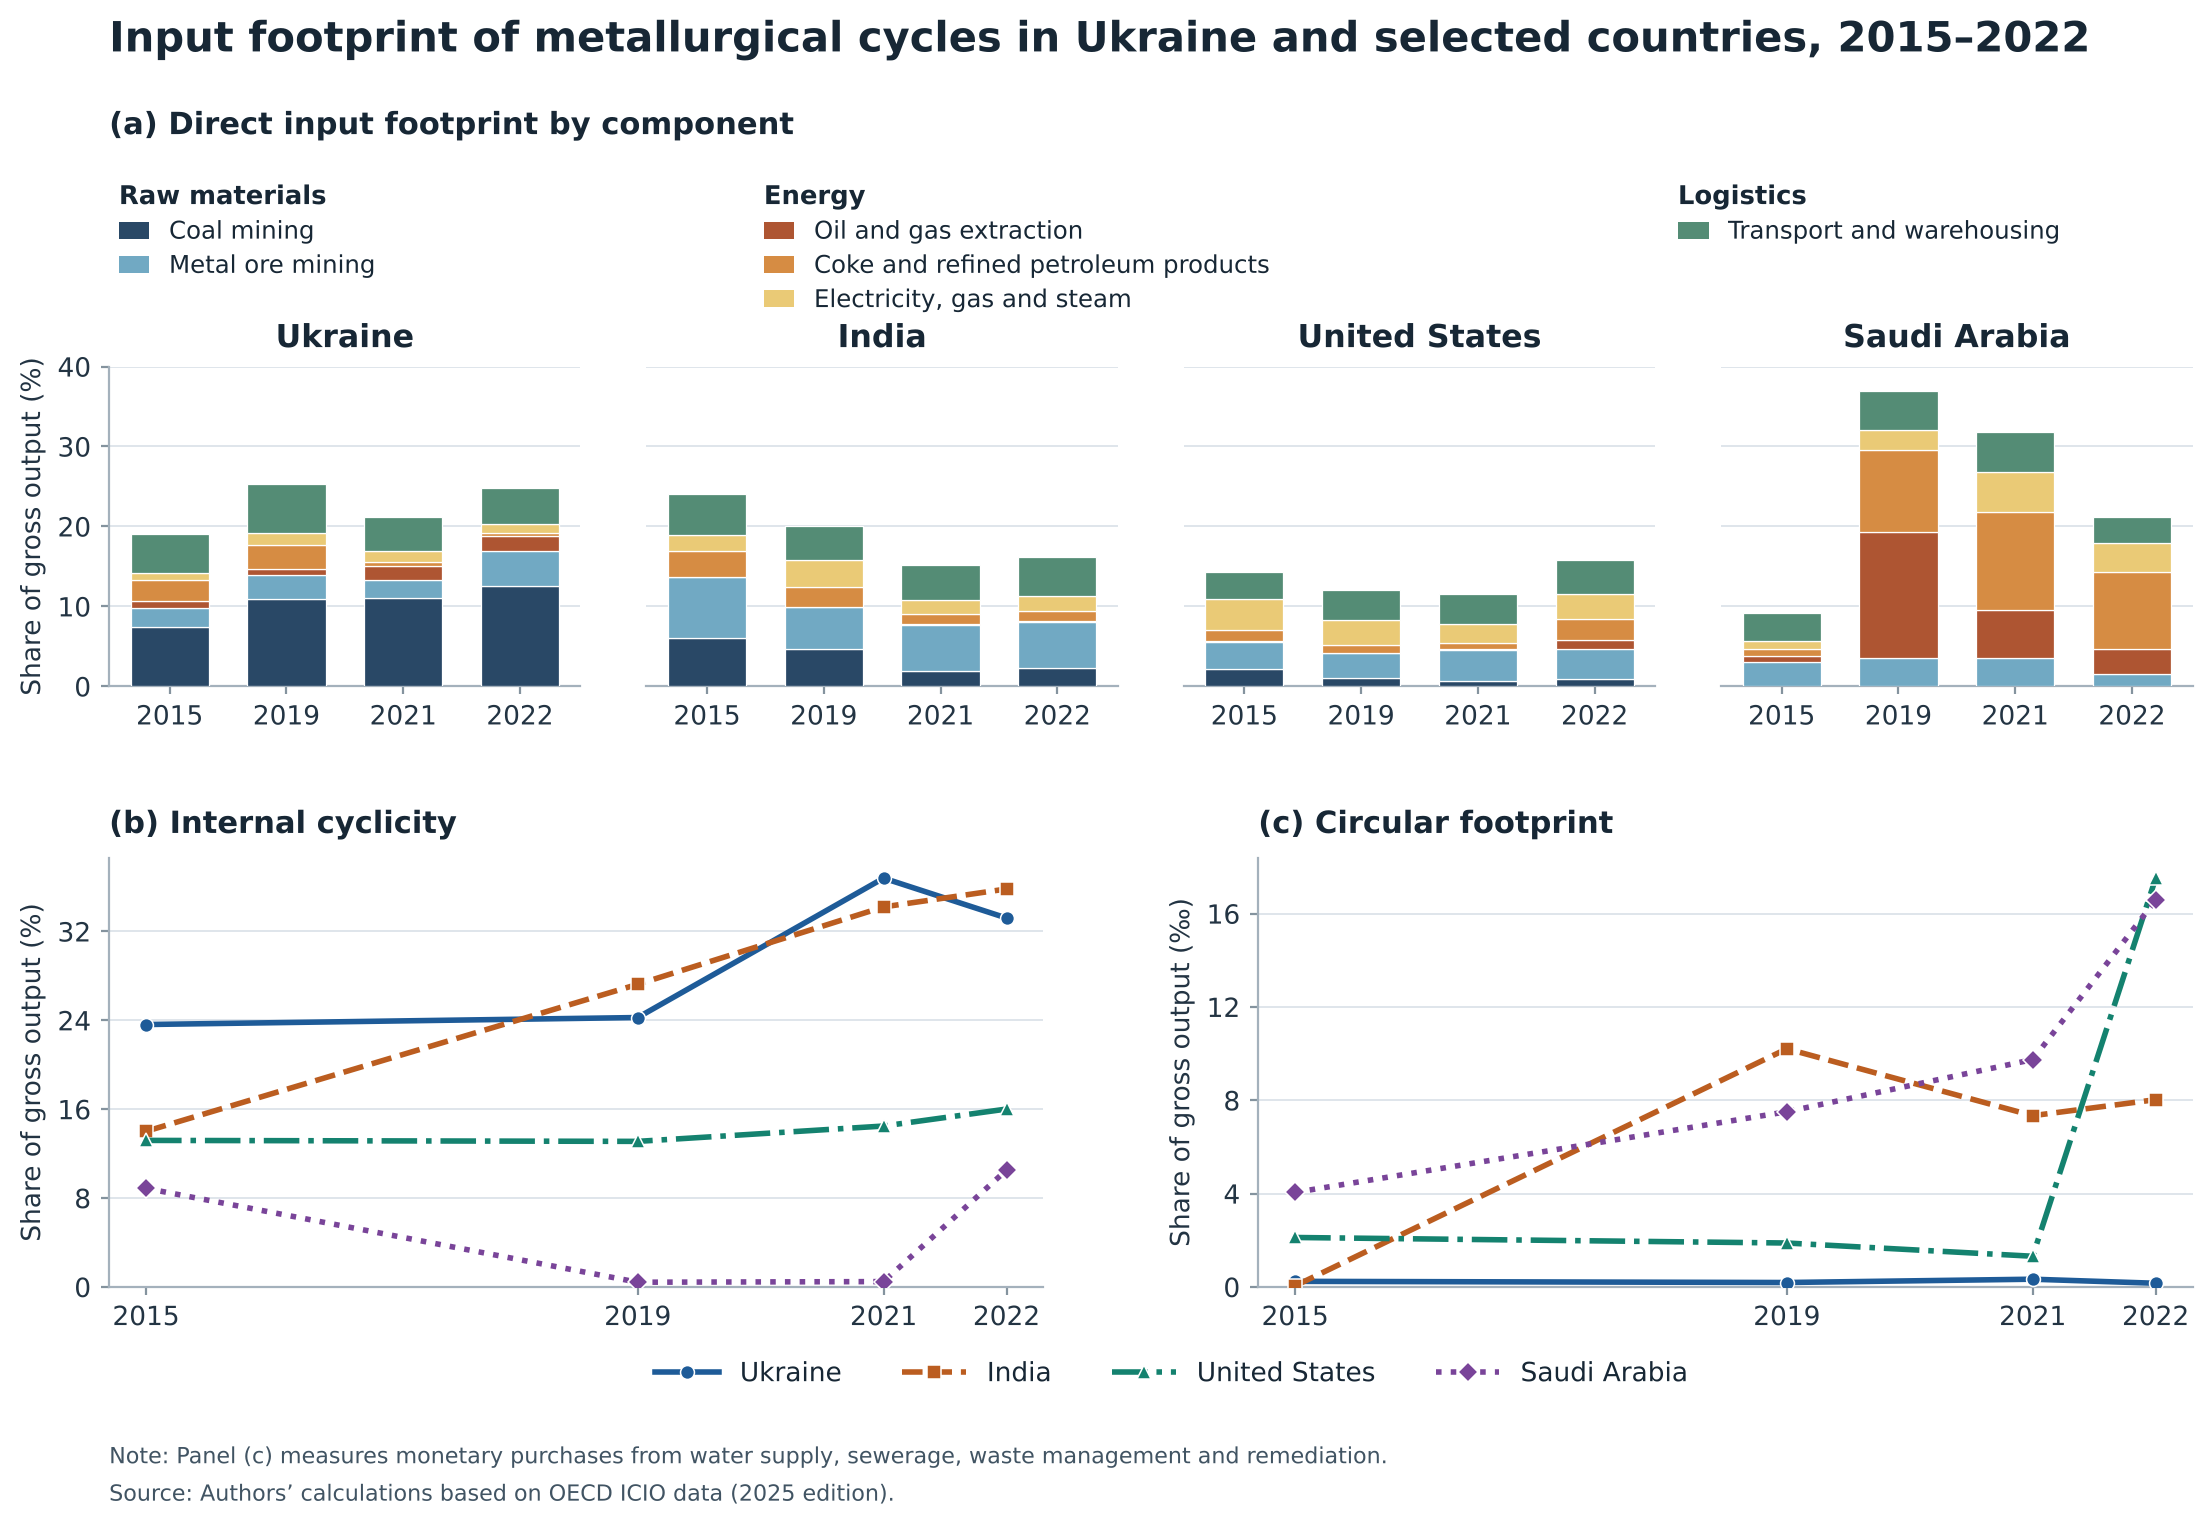

In [5]:
# Figure 2. Build, export, and display the figure in this cell.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

shell = get_ipython()
in_notebook = shell is not None and getattr(shell, "kernel", None) is not None
if in_notebook:
    shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

country_styles = {
    "UKR": ("#1E5B98", "o", "-"),
    "IND": ("#BB5D20", "s", "--"),
    "USA": ("#14826F", "^", "-."),
    "SAU": ("#794499", "D", ":"),
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 9.5,
    "axes.labelcolor": "#233443",
    "text.color": "#172735",
    "xtick.color": "#233443",
    "ytick.color": "#233443",
    "pdf.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig = plt.figure(figsize=(11.6, 7.8), facecolor="white")
    top = fig.add_gridspec(
        1, 4, left=.082, right=.98, bottom=.55, top=.755, wspace=.14
    )
    bottom = fig.add_gridspec(
        1, 2, left=.082, right=.98, bottom=.165, top=.44, wspace=.23
    )

    figure2_data = figure_2_table.set_index(["country", "year"])
    maximum = 100 * figure_2_table["selected_direct_components_share"].max()
    y_max = max(10, 10 * np.ceil(maximum * 1.04 / 10))

    bar_axes = []
    for index, country in enumerate(COUNTRIES):
        ax = fig.add_subplot(top[0, index], sharey=bar_axes[0] if bar_axes else None)
        bar_axes.append(ax)
        series = figure2_data.loc[country].loc[list(YEARS)]
        offsets = np.arange(len(YEARS))
        cumulative = np.zeros(len(YEARS))

        for metric, (label, _, color) in figure2_components.items():
            values = 100 * series[metric].to_numpy()
            ax.bar(
                offsets, values, bottom=cumulative, width=.67, color=color,
                edgecolor="white", linewidth=.45, label=label, zorder=3,
            )
            cumulative += values

        ax.set_ylim(0, y_max)
        ax.set_yticks(np.arange(0, y_max + 1, 10))
        ax.set_xticks(offsets, [str(year) for year in YEARS])
        ax.set_title(COUNTRY_NAMES[country], fontweight="semibold", pad=7)

        if index:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.spines["left"].set_visible(False)
        else:
            ax.set_ylabel("Share of gross output (%)")

    line_panels = [
        (
            "own_sector_direct_share", 100, "Share of gross output (%)",
            "(b) Internal cyclicity",
        ),
        (
            "circular_footprint_per_mille", 1, "Share of gross output (‰)",
            "(c) Circular footprint",
        ),
    ]
    line_axes = []
    for index, (metric, scale, ylabel, title) in enumerate(line_panels):
        ax = fig.add_subplot(bottom[0, index])
        line_axes.append(ax)

        for country in COUNTRIES:
            values = figure2_data.loc[country].loc[list(YEARS), metric]
            color, marker, linestyle = country_styles[country]
            ax.plot(
                YEARS, scale * values.to_numpy(), color=color, marker=marker,
                linestyle=linestyle, linewidth=2, markersize=5,
                label=COUNTRY_NAMES[country], markeredgecolor="white",
                markeredgewidth=.55, zorder=3,
            )

        ax.set_title(title, loc="left", fontweight="semibold", fontsize=11, pad=9)
        ax.set_ylabel(ylabel)
        ax.set_xticks(YEARS, [str(year) for year in YEARS])
        ax.set_xlim(min(YEARS) - .3, max(YEARS) + .3)
        ax.set_ylim(bottom=0)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    for ax in (*bar_axes, *line_axes):
        ax.grid(axis="y", color="#DCE3E9", linewidth=.65, zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E")
        for pos in ("bottom", "left"):
            ax.spines[pos].set_color("#A4B1BC")

    fig.text(
        .082, .957,
        "Input footprint of metallurgical cycles in Ukraine and selected countries, 2015–2022",
        fontsize=15, fontweight="bold", ha="left",
    )
    fig.text(
        .082, .904, "(a) Direct input footprint by component",
        fontsize=11, fontweight="semibold",
    )

    group_positions = (.082, .360, .754)
    for (group_name, group), position in zip(figure2_groups.items(), group_positions):
        handles = [Patch(facecolor=color, label=label) for label, _, color in group.values()]
        legend = fig.legend(
            handles=handles, title=group_name, alignment="left", loc="upper left",
            bbox_to_anchor=(position, .878), fontsize=8.8, title_fontsize=9.3,
            frameon=False, borderaxespad=0, handlelength=1.25, labelspacing=.40,
        )
        legend.get_title().set_fontweight("semibold")

    fig.legend(
        *line_axes[0].get_legend_handles_labels(), ncol=4, frameon=False,
        loc="center", bbox_to_anchor=(.54, .109), columnspacing=2.3, handlelength=2.4,
    )
    fig.text(
        .082, .052,
        "Note: Panel (c) measures monetary purchases from water supply, sewerage, "
        "waste management and remediation.",
        fontsize=8, color="#415463",
    )
    fig.text(
        .082, .028, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
        fontsize=8, color="#415463",
    )

    figure_2_png = OUTPUT_DIR / "Figure_2_Input_Footprint.png"
    figure_2_pdf = OUTPUT_DIR / "Figure_2_Input_Footprint.pdf"
    fig.savefig(figure_2_png, dpi=400, facecolor="white")
    fig.savefig(figure_2_pdf, facecolor="white")

    if in_notebook:
        plt.show()
    else:
        with BytesIO() as preview:
            fig.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(fig)

In [6]:
# Figure 3. Calculate output destinations as shares of C24A gross output.
figure_3_components = {
    "domestic_other_intermediate_sales_share": "Production footprint",
    "own_sector_direct_share": "Internal cyclicity",
    "reported_export_share": "Export footprint",
    "domestic_final_use_share": "Domestic final use",
}

figure_3_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
figure_3_table = direct.set_index(["country", "year"]).loc[figure_3_cases, [
    "steel_gross_output", *figure_3_components, "sales_residual_share",
    "domestic_fabricated_metals_destination_share", "domestic_water_waste_destination_share",
]].reset_index()
figure_3_table.insert(1, "country_name", figure_3_table["country"].map(COUNTRY_NAMES))
figure_3_table["accounted_output_share"] = figure_3_table[list(figure_3_components)].sum(axis=1)

# Retain the original output denominator and check the recorded balance gap.
figure_3_balance_gap = 1 - figure_3_table["accounted_output_share"]
np.testing.assert_allclose(
    figure_3_balance_gap, figure_3_table["sales_residual_share"], rtol=0, atol=1e-12,
)
if figure_3_balance_gap.abs().gt(BALANCE_REL_TOL).any():
    raise ValueError("Figure 3: output balance exceeds the tolerance in Data preparation.")

figure_3_preview = figure_3_table[["country_name", "year"]].rename(
    columns={"country_name": "Country", "year": "Year"}
)
for metric, label in figure_3_components.items():
    figure_3_preview[f"{label} (%)"] = 100 * figure_3_table[metric]
figure_3_preview["Balance gap (pp)"] = 100 * figure_3_balance_gap

figure_3_csv = OUTPUT_DIR / "figure_3_output_destinations.csv"
figure_3_table.to_csv(figure_3_csv, index=False, encoding="utf-8-sig")
display(figure_3_preview.round(4))

,Country,Year,Production footprint (%),Internal cyclicity (%),Export footprint (%),Domestic final use (%),Balance gap (pp)
0,Ukraine,2015,37.1417,23.6226,39.2080,0.0276,0.0001
1,Ukraine,2019,52.3989,24.2520,23.3058,0.0433,-0.0000
2,Ukraine,2021,26.2325,36.8001,36.9434,0.0240,0.0000
3,Ukraine,2022,31.7823,33.2107,34.9499,0.0571,0.0001
4,India,2015,69.3364,14.0098,10.9322,5.7216,0.0001
5,India,2019,64.2379,27.2436,7.7770,0.7415,0.0000
6,India,2021,54.6714,34.2097,10.1771,0.9418,0.0000
7,India,2022,55.3415,35.8249,7.9335,0.9001,0.0000
8,United States,2015,75.5427,13.1914,10.0553,1.2107,-0.0001
9,United States,2019,78.5131,13.1040,7.3589,1.0240,-0.0000


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


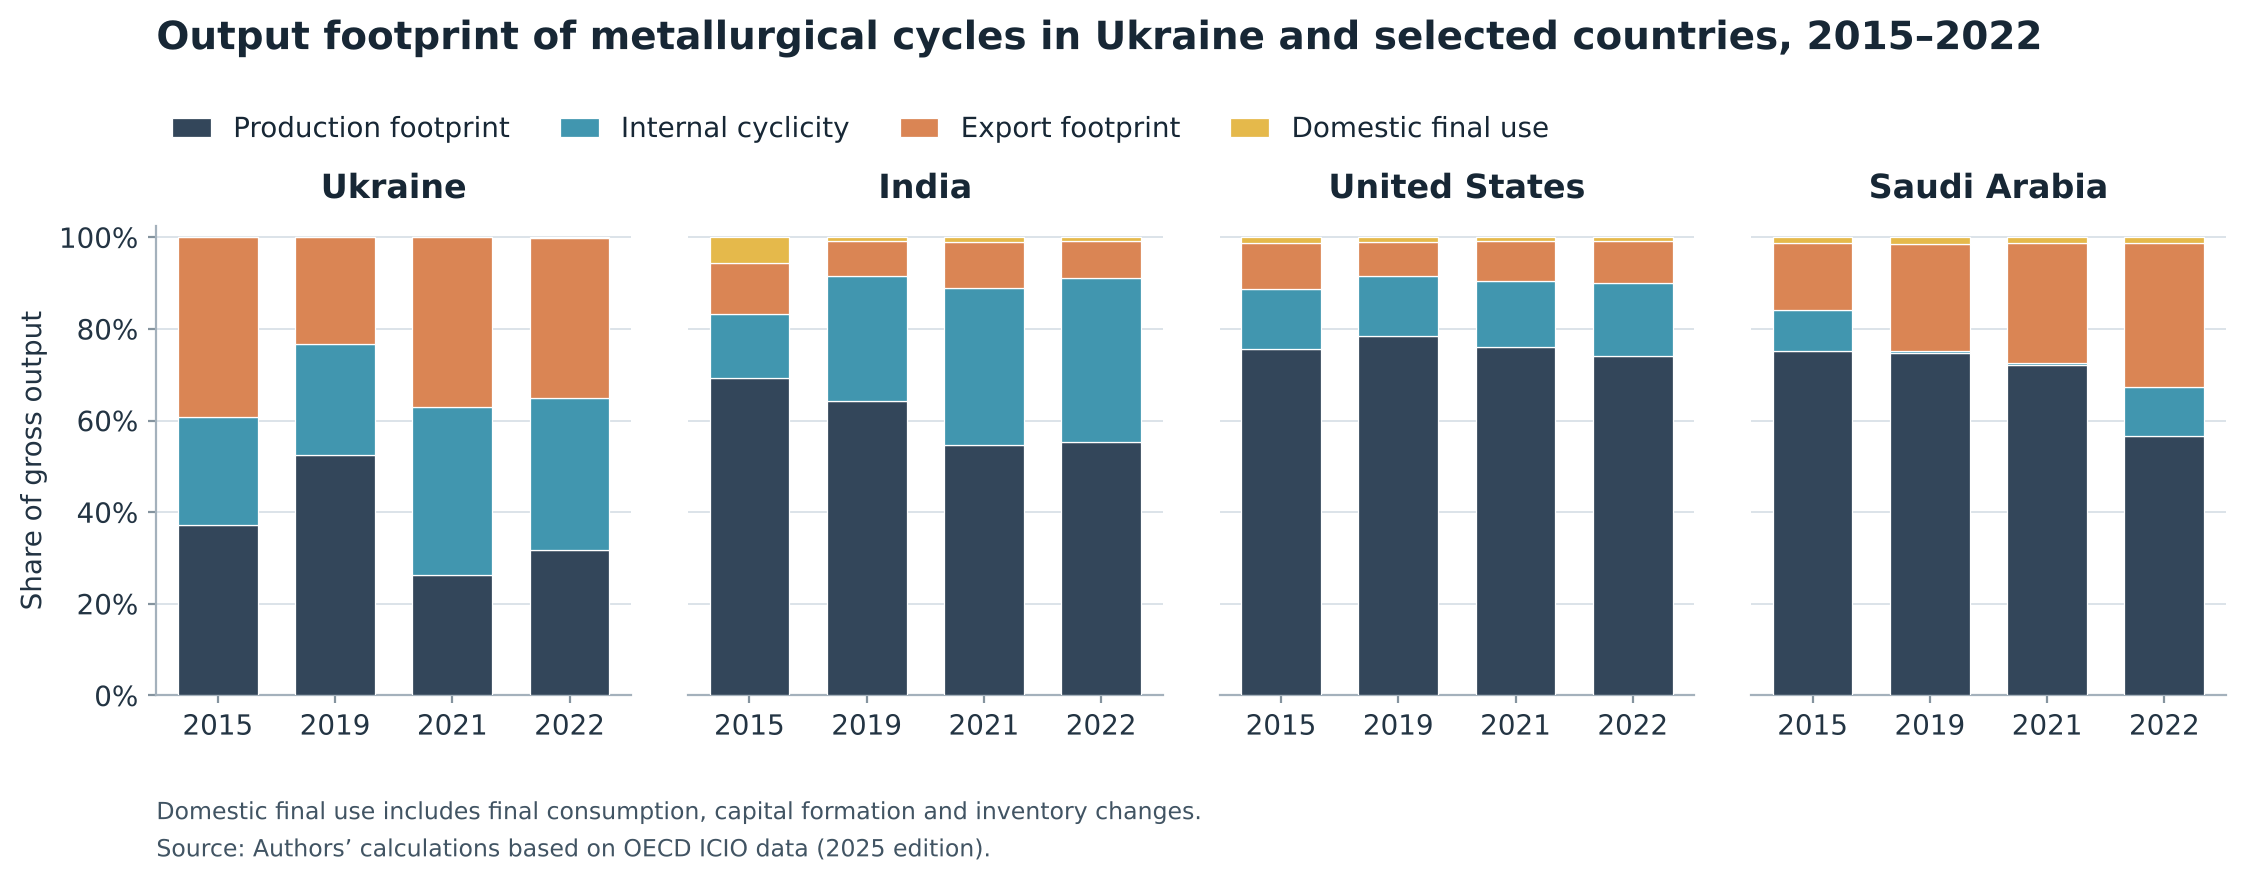

In [7]:
# Figure 3. Build, export, and display the figure in this cell.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.ticker import PercentFormatter

figure_3_shell = get_ipython()
figure_3_inline = figure_3_shell is not None and getattr(figure_3_shell, "kernel", None) is not None
if figure_3_inline:
    figure_3_shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

figure_3_colors = {
    "domestic_other_intermediate_sales_share": "#33465A",
    "own_sector_direct_share": "#4196AF",
    "reported_export_share": "#DA8554",
    "domestic_final_use_share": "#E5B94B",
}

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.labelcolor": "#233443", "text.color": "#172735",
                     "xtick.color": "#233443", "ytick.color": "#233443",
                     "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}):
    figure_3, axes = plt.subplots(1, len(COUNTRIES), sharey=True, figsize=(11.6, 4.65), facecolor="white")
    figure_3.subplots_adjust(left=.088, right=.98, bottom=.225, top=.73, wspace=.12)
    figure_3_data = figure_3_table.set_index(["country", "year"])
    positions = np.arange(len(YEARS))
    for ax, country in zip(axes, COUNTRIES):
        series = figure_3_data.loc[country].loc[list(YEARS)]
        positive = np.zeros(len(YEARS))
        negative = np.zeros(len(YEARS))
        for metric, label in figure_3_components.items():
            values = series[metric].to_numpy()
            bottom = np.where(values >= 0, positive, negative)
            ax.bar(positions, values, bottom=bottom, width=.68, label=label,
                   color=figure_3_colors[metric], edgecolor="white", linewidth=.45, zorder=3)
            positive += np.maximum(values, 0)
            negative += np.minimum(values, 0)
        ax.set_title(COUNTRY_NAMES[country], fontweight="semibold", pad=10)
        ax.set_xticks(positions, [str(year) for year in YEARS])
        ax.set_yticks(np.linspace(0, 1, 6))
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        ax.grid(axis="y", color="#DCE3E9", linewidth=.7)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E")
        for spine in ("left", "bottom"):
            ax.spines[spine].set_color("#A4B1BC")
        if ax is not axes[0]:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.spines["left"].set_visible(False)

    positive_limit = figure_3_table[list(figure_3_components)].clip(lower=0).sum(axis=1).max()
    negative_limit = figure_3_table[list(figure_3_components)].clip(upper=0).sum(axis=1).min()
    axes[0].set_ylim(min(0, 1.08 * negative_limit), max(1.025, 1.01 * positive_limit))
    axes[0].set_ylabel("Share of gross output")
    figure_3.text(.088, .92, "Output footprint of metallurgical cycles in Ukraine and selected countries, 2015–2022",
                  fontsize=14, fontweight="bold")
    figure_3.legend(*axes[0].get_legend_handles_labels(), ncol=4, frameon=False,
                    loc="upper left", bbox_to_anchor=(.084, .875), columnspacing=1.8,
                    handlelength=1.4)
    figure_3.text(.088, .092, "Domestic final use includes final consumption, capital formation and inventory changes.",
                  fontsize=8.5, color="#415463")
    figure_3.text(.088, .052, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
                  fontsize=8.5, color="#415463")

    figure_3_png = OUTPUT_DIR / "Figure_3_Output_Footprint.png"
    figure_3_pdf = OUTPUT_DIR / "Figure_3_Output_Footprint.pdf"
    figure_3.savefig(figure_3_png, dpi=400, facecolor="white")
    figure_3.savefig(figure_3_pdf, facecolor="white")
    if figure_3_inline:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_3.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_3)

In [8]:
def solve_domestic_model(block, requested_sectors):
    x = block.loc["OUTPUT", requested_sectors].astype(float)
    if x.isna().any() or x.lt(0).any():
        raise ValueError("Model requires nonmissing, nonnegative output by sector")
    inactive = x.index[x.eq(0)]
    z_all = block.loc[sectors, sectors]
    if z_all.loc[inactive].ne(0).any().any() or z_all.loc[:, inactive].ne(0).any().any():
        raise ValueError("A zero-output sector has nonzero domestic flows")

    active = x.index[x.gt(0)]
    x = x.loc[active]
    a = block.loc[active, active].div(x, axis="columns")
    matrix = a.to_numpy()
    rho = np.abs(np.linalg.eigvals(matrix)).max()
    if rho >= 1:
        raise ValueError(f"Nonproductive domestic coefficient matrix (rho={rho:.6g})")
    identity = np.eye(len(active))
    inverse = np.linalg.solve(identity - matrix, identity)
    np.testing.assert_allclose((identity - matrix) @ inverse, identity, rtol=0, atol=1e-10)
    l = pd.DataFrame(inverse, index=active, columns=active)
    return x, a, l, rho


model_rows = []
matrix_frames = []
requirement_frames = []
dependence_frames = []
models = {}
for (country, year), block in blocks.items():
    requested_models = {"common12": common_sectors}
    if block.loc["OUTPUT", sectors].notna().all():
        requested_models["full_available"] = sectors
    for scope, requested in requested_models.items():
        x, a, l, rho = solve_domestic_model(block, requested)
        models[country, year, scope] = (x, a, l)
        column = l[FOCUS]
        own = l.loc[FOCUS, FOCUS]
        external = column.drop(FOCUS)
        components = external.groupby(sector_group).sum()
        np.testing.assert_allclose(
            [external.sum(), components.sum()], column.sum() - own, rtol=0, atol=1e-10
        )
        dimensions = {"country": country, "year": year, "scope": scope}
        model_rows.append({
            **dimensions, "active_sector_count": len(x), "spectral_radius": rho,
            "output_multiplier": column.sum(), "own_sector_requirement": own,
            "own_sector_feedback_requirement": own - 1,
            "other_domestic_sector_requirement": external.sum(),
            "es_identity_gap": external.sum() - (column.sum() - own),
        })
        requirement_frames.append(
            column.rename("output_requirement").rename_axis("supplier_sector").reset_index().assign(**dimensions)
        )
        dependence_frames.append(
            components.rename("other_domestic_sector_requirement")
            .rename_axis("component").reset_index().assign(**dimensions)
        )
        matrix_frames.append(
            pd.DataFrame({
                "supplier_sector": np.repeat(x.index.to_numpy(), len(x)),
                "buyer_sector": np.tile(x.index.to_numpy(), len(x)),
                "direct_input_coefficient": a.to_numpy().ravel(),
                "total_output_requirement": l.to_numpy().ravel(),
            }).assign(**dimensions)
        )

output_models = pd.DataFrame(model_rows)
matrices = pd.concat(matrix_frames, ignore_index=True)
requirements = pd.concat(requirement_frames, ignore_index=True)
dependence_by_component = pd.concat(dependence_frames, ignore_index=True)
scope_check = output_models.query("year == 2022").pivot(
    index="country", columns="scope",
    values=["output_multiplier", "own_sector_requirement", "other_domestic_sector_requirement"],
).reindex(COUNTRIES)
display(scope_check.round(4))

output_multiplier                own_sector_requirement  \
scope            common12 full_available               common12   
country                                                           
UKR                2.2487         2.5483                 1.5166   
IND                1.9920         2.1962                 1.5712   
USA                1.6678         2.1078                 1.1957   
SAU                1.6823         1.8991                 1.1186   

                       other_domestic_sector_requirement                 
scope   full_available                          common12 full_available  
country                                                                  
UKR             1.5210                            0.7321         1.0273  
IND             1.5766                            0.4208         0.6195  
USA             1.1970                            0.4720         0.9108  
SAU             1.1187                            0.5638         0.7804

In [9]:
# Figure 4. Divide each industry’s GVA by its own gross output.
figure_4_sectors = {
    "COAL": "Coal mining",
    "OILGAS": "Oil and gas extraction",
    "ORES": "Metal ore mining",
    "COKE": "Coke and refined petroleum products",
    "METAL": "Basic iron and steel",
    "FABMET": "Fabricated metal products",
}
va_industry_frames = []
va_direct_by_case = {}
for (country, year), prepared in prepared_blocks.items():
    gross_output = prepared["x"]
    industry_gva = prepared["va"]
    direct_share = ratio(industry_gva, gross_output)
    va_direct_by_case[country, year] = direct_share
    va_industry_frames.append(pd.DataFrame({
        "country": country, "year": year, "sector": sectors,
        "va_direct_share": direct_share, "gross_output": gross_output, "gva": industry_gva,
    }))

va_industry = pd.concat(va_industry_frames, ignore_index=True)
# Retain the original export covering all 13 industry groups.
va_direct = va_industry[["country", "year", "sector", "va_direct_share"]].copy()

figure_4_cases = pd.MultiIndex.from_product(
    [COUNTRIES, YEARS, figure_4_sectors], names=["country", "year", "sector"],
)
figure_4_table = va_industry.set_index(["country", "year", "sector"]).loc[figure_4_cases].reset_index()
figure_4_table.insert(1, "country_name", figure_4_table["country"].map(COUNTRY_NAMES))
figure_4_codes = mapping.set_index("sector")["oecd_icio_code"]
figure_4_table.insert(4, "oecd_icio_code", figure_4_table["sector"].map(figure_4_codes))
figure_4_table.insert(5, "sector_name", figure_4_table["sector"].map(figure_4_sectors))
figure_4_table["va_direct_share_pct"] = 100 * figure_4_table["va_direct_share"]
figure_4_table["status"] = np.where(figure_4_table["gross_output"].eq(0), "zero_output", "observed")

figure_4_csv = OUTPUT_DIR / "figure_4_direct_gva_table.csv"
figure_4_table.to_csv(figure_4_csv, index=False, encoding="utf-8-sig")
figure_4_preview = figure_4_table.pivot(
    index=["country", "year"], columns="sector", values="va_direct_share_pct",
).reindex(pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"]))
figure_4_preview = (
    figure_4_preview[list(figure_4_sectors)]
    .rename(columns=figure_4_sectors, index=COUNTRY_NAMES, level="country")
    .rename_axis(index=["Country", "Year"], columns=None)
)
display(figure_4_preview.round(2).astype(object).where(figure_4_preview.notna(), "—"))

Coal mining Oil and gas extraction Metal ore mining  \
Country       Year                                                       
Ukraine       2015       20.89                  59.02            89.96   
              2019       34.16                  62.85            90.05   
              2021       25.57                   40.8            90.07   
              2022       22.33                  35.64            90.01   
India         2015       59.05                   58.6             44.3   
              2019       61.68                  75.55            44.45   
              2021       62.69                  76.62            47.61   
              2022       60.19                  74.48            45.72   
United States 2015        54.9                  57.56             38.4   
              2019       60.33                  48.66            39.61   
              2021       64.81                  48.44            45.06   
              2022       65.13                  48.68            45.28   
Saudi Arabia  2015           —                  92.09            76.48   
              2019           —                  85.17            69.33   
              2021           —                   84.0            67.16   
              2022           —                  87.82             70.3   

                   Coke and refined petroleum products Basic iron and steel  \
Country       Year                                                            
Ukraine       2015                               11.07                13.52   
              2019                               10.81                12.16   
              2021                               10.39                13.59   
              2022                                8.99                11.75   
India         2015                               21.23                13.34   
              2019                               18.87                16.57   
              2021                               22.72                19.96   
              2022                                20.2                17.75   
United States 2015                               28.04                24.73   
              2019                               24.97                26.47   
              2021                               24.58                28.62   
              2022                               26.11                 28.5   
Saudi Arabia  2015                                49.8                21.02   
              2019                               34.83                16.22   
              2021                               27.71                17.31   
              2022                               41.65                18.19   

                   Fabricated metal products  
Country       Year                            
Ukraine       2015                     20.22  
              2019                      19.6  
              2021                     17.39  
              2022                     15.05  
India         2015                     30.66  
              2019                     29.59  
              2021                      27.4  
              2022                     24.36  
United States 2015                     39.71  
              2019                     39.87  
              2021                     35.91  
              2022                     39.11  
Saudi Arabia  2015                     55.74  
              2019                      49.8  
              2021                     48.92  
              2022                     51.27

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


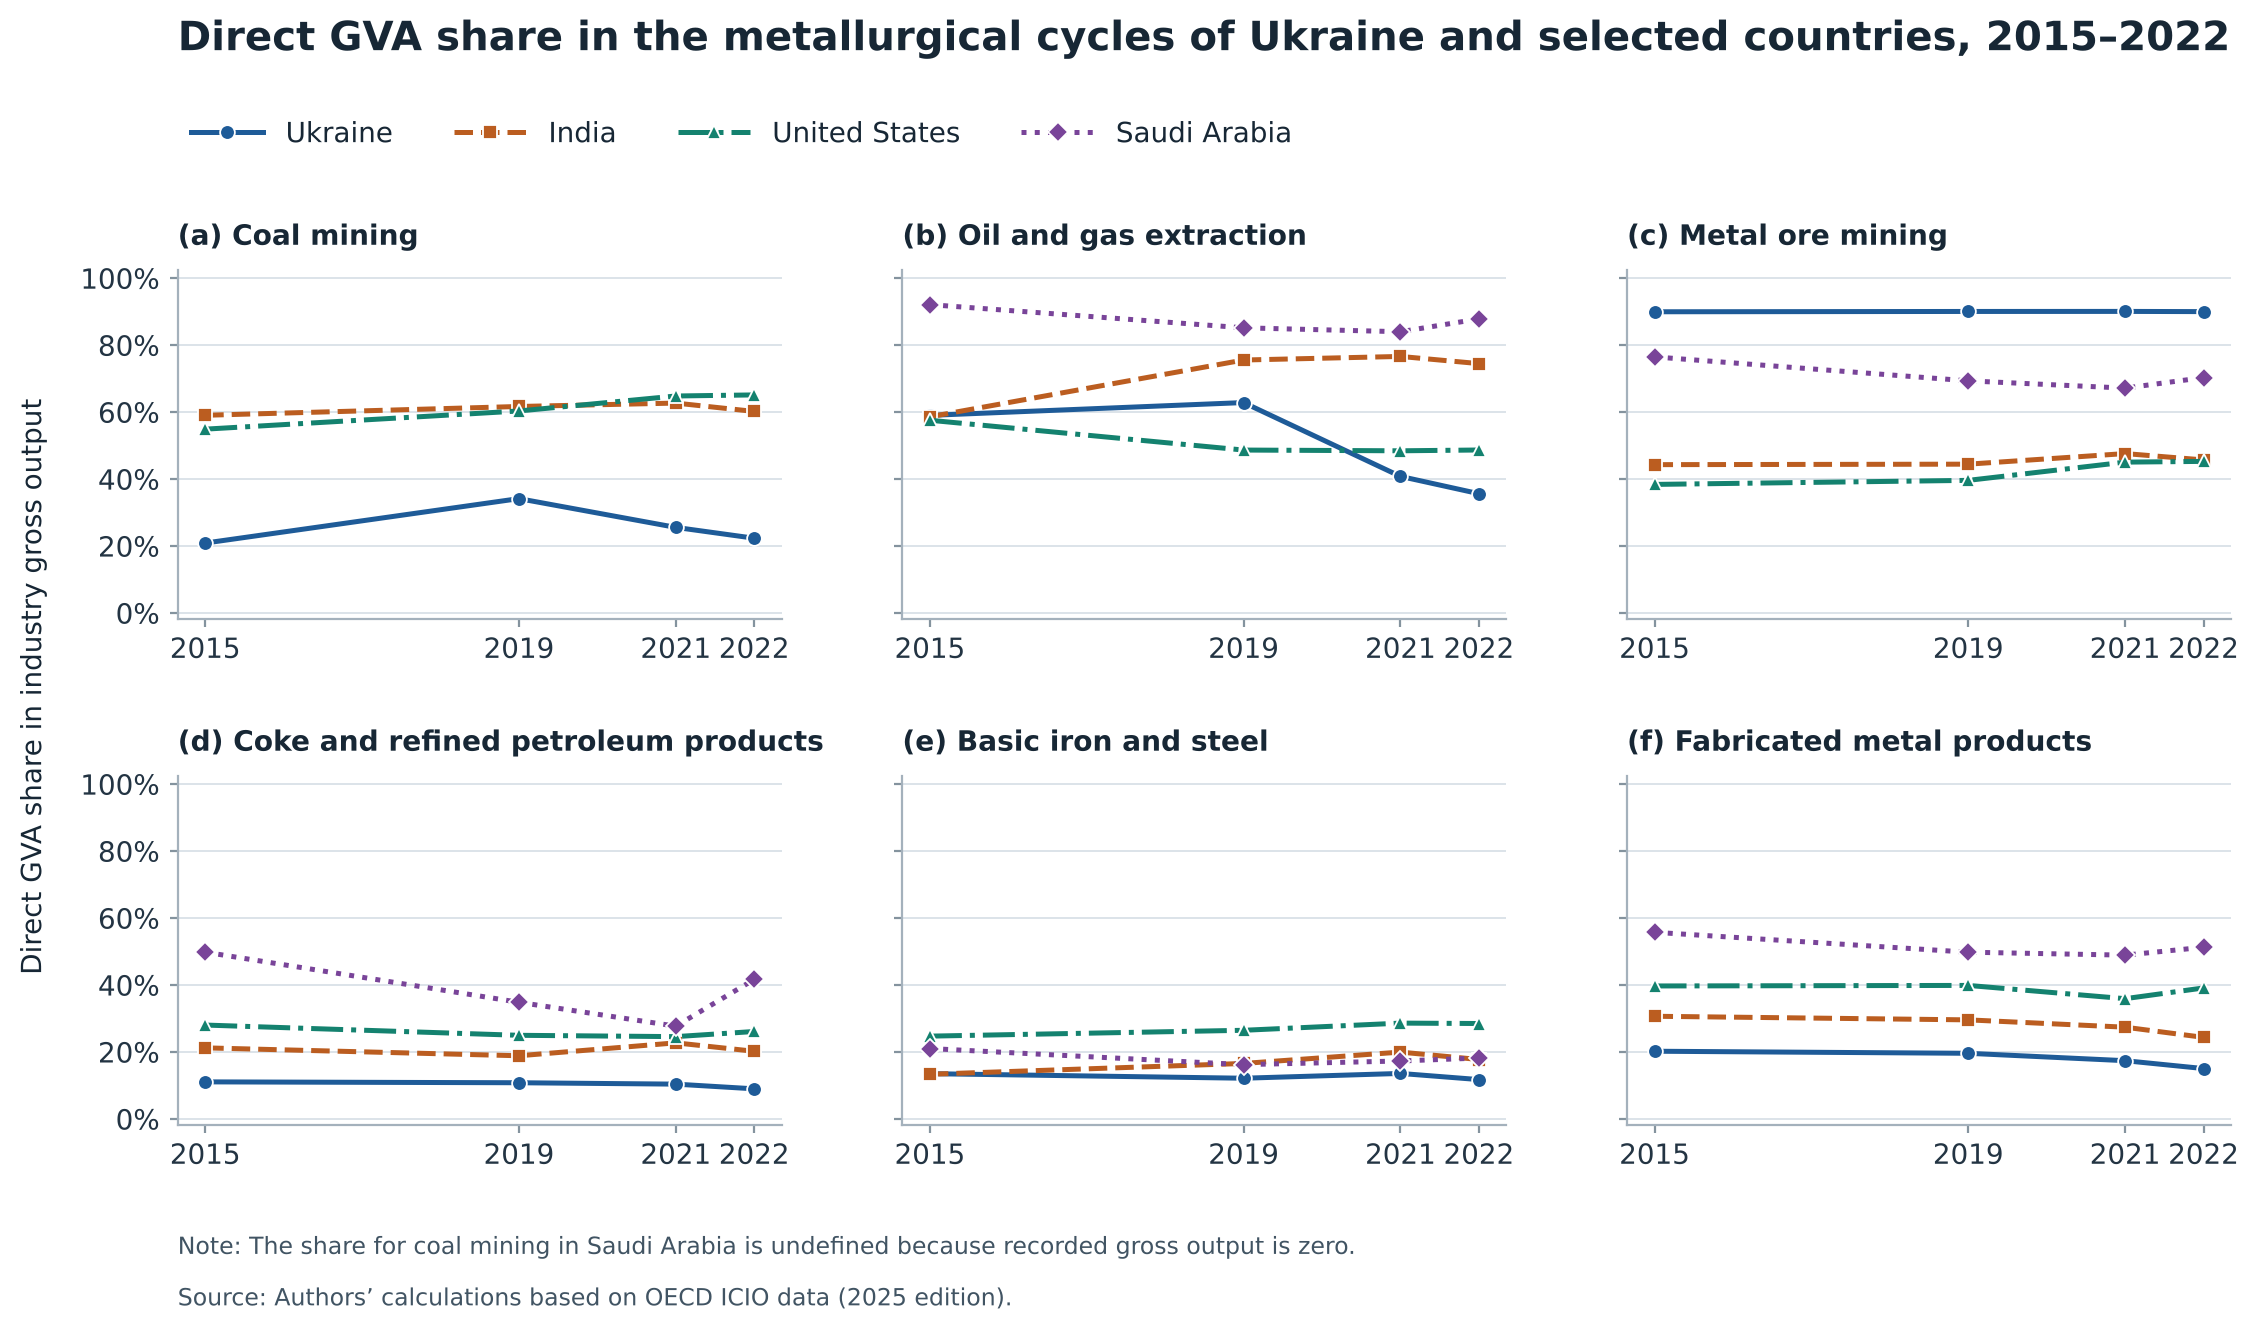

In [10]:
# Figure 4. Build, export, and display the figure in this cell.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.ticker import PercentFormatter

figure_4_shell = get_ipython()
figure_4_inline = figure_4_shell is not None and getattr(figure_4_shell, "kernel", None) is not None
if figure_4_inline:
    figure_4_shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

figure_4_styles = {
    "UKR": ("#1E5B98", "o", "-"),
    "IND": ("#BB5D20", "s", "--"),
    "USA": ("#14826F", "^", "-."),
    "SAU": ("#794499", "D", ":"),
}

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.labelcolor": "#233443", "text.color": "#172735",
                     "xtick.color": "#233443", "ytick.color": "#233443",
                     "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}):
    figure_4, panels = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(11.6, 6.95),
                                    facecolor="white")
    figure_4.subplots_adjust(left=.085, right=.97, bottom=.175, top=.79, wspace=.20, hspace=.45)
    figure_4_data = figure_4_table.set_index(["sector", "country", "year"]).sort_index()
    for index, (ax, (sector, label)) in enumerate(zip(panels.flat, figure_4_sectors.items())):
        for country in COUNTRIES:
            values = figure_4_data.loc[(sector, country), "va_direct_share"].reindex(YEARS)
            color, marker, linestyle = figure_4_styles[country]
            ax.plot(YEARS, values.to_numpy(), color=color, marker=marker, linestyle=linestyle,
                    linewidth=1.8, markersize=5.3, markeredgecolor="white", markeredgewidth=.65,
                    label=COUNTRY_NAMES[country], zorder=3)
        ax.set_title(f"({chr(97 + index)}) {label}", loc="left", fontweight="semibold", fontsize=10.1, pad=9)
        ax.set_xticks(YEARS, [str(year) for year in YEARS])
        ax.set_xlim(min(YEARS) - .35, max(YEARS) + .35)
        ax.grid(axis="y", color="#DCE3E9", linewidth=.7)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E", labelbottom=True)
        for spine in ("left", "bottom"):
            ax.spines[spine].set_color("#A4B1BC")

    min_ratio = min(0, np.floor(5 * figure_4_table["va_direct_share"].min()) / 5)
    max_ratio = max(1, np.ceil(5 * figure_4_table["va_direct_share"].max()) / 5)
    panels[0, 0].set_yticks(np.arange(min_ratio, max_ratio + .1, .2))
    panels[0, 0].set_ylim(min_ratio - .017, max_ratio + .025)
    panels[0, 0].yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    figure_4.text(.017, .49, "Direct GVA share in industry gross output", rotation=90, va="center")
    figure_4.text(.085, .948, "Direct GVA share in the metallurgical cycles of Ukraine and selected countries, 2015–2022",
                  fontsize=14.5, fontweight="bold")
    figure_4.legend(*panels[0, 0].get_legend_handles_labels(), ncol=4, frameon=False,
                    loc="upper left", bbox_to_anchor=(.08, .915), columnspacing=2.2, handlelength=2.6)
    figure_4.text(.085, .082, "Note: The share for coal mining in Saudi Arabia is undefined because recorded gross output is zero.",
                  fontsize=8.5, color="#415463")
    figure_4.text(.085, .045, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
                  fontsize=8.5, color="#415463")

    figure_4_png = OUTPUT_DIR / "Figure_4_Direct_GVA_Share.png"
    figure_4_pdf = OUTPUT_DIR / "Figure_4_Direct_GVA_Share.pdf"
    figure_4.savefig(figure_4_png, dpi=400, facecolor="white")
    figure_4.savefig(figure_4_pdf, facecolor="white")
    if figure_4_inline:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_4.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_4)

In [11]:
va_summary_frames = []
va_contribution_frames = []
for (country, year), block in blocks.items():
    v_source = va_direct_by_case[country, year]
    key = (country, year, "full_available")
    if key not in models:
        continue
    x, _, l = models[key]
    v = v_source.loc[x.index]
    if v.isna().any():
        continue
    va_matrix = l.mul(v, axis="index")
    total = va_matrix.sum(axis=0)
    own = pd.Series(np.diag(va_matrix), index=x.index)
    feedback = own - v
    outside = total - own
    norm = ratio(total, v)
    np.testing.assert_allclose(v + feedback + outside, total, rtol=0, atol=1e-10)
    np.testing.assert_allclose(
        (norm * v).dropna(), total.loc[norm.dropna().index], rtol=0, atol=1e-10
    )

    imp = block.loc["IMP_IC", x.index].astype(float) / x
    tls = block.loc["TLS", x.index].astype(float) / x
    import_requirement = l.T @ imp
    tax_requirement = l.T @ tls
    unit_residual = 1 - total - import_requirement - tax_requirement
    if not unit_residual.isna().any():
        # Source values are rounded and aggregated.
        np.testing.assert_allclose(unit_residual, 0, rtol=0, atol=5e-5)

    va_summary_frames.append(pd.DataFrame({
        "country": country, "year": year, "scope": "full_available", "sector": x.index,
        "va_direct": v, "va_own_feedback": feedback, "va_other_domestic": outside,
        "va_total_domestic": total, "va_multiplier_normalized": norm,
        "va_other_share_in_total": ratio(outside, total),
        "imported_intermediate_requirement": import_requirement,
        "taxes_less_subsidies_requirement": tax_requirement, "unit_balance_residual": unit_residual,
    }))
    va_contribution_frames.append(
        va_matrix[FOCUS].rename("va_contribution").rename_axis("supplier_sector")
        .reset_index().assign(country=country, year=year, scope="full_available")
    )

va_all_sectors = pd.concat(va_summary_frames, ignore_index=True)
va_by_supplier = pd.concat(va_contribution_frames, ignore_index=True)
va_steel = va_all_sectors.loc[va_all_sectors["sector"].eq(FOCUS)].copy()
va_display = ["va_direct", "va_own_feedback", "va_other_domestic", "va_total_domestic",
              "va_multiplier_normalized", "va_other_share_in_total"]
display(va_steel.set_index("country").loc[list(COUNTRIES), va_display].round(4))

,va_direct,va_own_feedback,va_other_domestic,va_total_domestic,va_multiplier_normalized,va_other_share_in_total
country,,,,,,
UKR,0.1352,0.0461,0.3429,0.5242,3.8780,0.6542
UKR,0.1216,0.0434,0.4347,0.5997,4.9330,0.7248
UKR,0.1359,0.0832,0.4240,0.6431,4.7330,0.6594
UKR,0.1175,0.0612,0.4046,0.5834,4.9641,0.6936
IND,0.1334,0.0235,0.3200,0.4768,3.5744,0.6710
IND,0.1657,0.0668,0.3786,0.6110,3.6875,0.6196
IND,0.1996,0.1071,0.2985,0.6053,3.0318,0.4932
IND,0.1775,0.1023,0.3133,0.5931,3.3419,0.5282
USA,0.2473,0.0391,0.5337,0.8201,3.3163,0.6508


In [12]:
# Tables A1 and A2, on the full domestic industry model.
from IPython.display import Markdown
figure_5_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
a1_requirements = (
    requirements.query("scope == 'full_available'")
    .pivot(index=["country", "year"], columns="supplier_sector", values="output_requirement")
    .reindex(index=figure_5_cases, columns=sectors)
)
# Fill only the structural gaps for verified inactive supplying industries.
for key, case in prepared_blocks.items():
    inactive = case["x"].index[case["x"].eq(0)]
    if len(inactive):
        a1_requirements.loc[key, inactive] = 0.0
if a1_requirements.isna().any().any():
    raise ValueError("Table A1 has missing active-industry requirements.")

a1_totals = output_models.query("scope == 'full_available'").set_index(["country", "year"])
a1_totals = a1_totals.loc[figure_5_cases, [
    "scope", "active_sector_count", "own_sector_requirement",
    "other_domestic_sector_requirement", "output_multiplier",
]]
table_a1 = a1_requirements.join(a1_totals).reset_index()
table_a1.insert(1, "country_name", table_a1["country"].map(COUNTRY_NAMES))
np.testing.assert_allclose(
    table_a1[sectors].sum(axis=1), table_a1["output_multiplier"], rtol=0, atol=1e-10,
)
np.testing.assert_allclose(
    table_a1[FOCUS], table_a1["own_sector_requirement"], rtol=0, atol=1e-10,
)

a2_cases = pd.MultiIndex.from_product(
    [COUNTRIES, YEARS, figure_4_sectors], names=["country", "year", "sector"],
)
a2_results = va_all_sectors.set_index(["country", "year", "sector"]).drop(columns="scope")
a2_output = va_industry.set_index(["country", "year", "sector"])["gross_output"]
table_a2 = a2_results.reindex(a2_cases).join(a2_output).reset_index()
table_a2.insert(1, "country_name", table_a2["country"].map(COUNTRY_NAMES))
table_a2.insert(4, "sector_name", table_a2["sector"].map(figure_4_sectors))
table_a2.insert(5, "oecd_icio_code", table_a2["sector"].map(mapping.set_index("sector")["oecd_icio_code"]))
table_a2.insert(6, "scope", "full_available")
table_a2["status"] = np.where(
    table_a2["gross_output"].eq(0), "zero_output",
    np.where(table_a2["va_direct"].gt(0), "observed", "nonpositive_direct_gva"),
)
table_a2["va_indirect_domestic"] = table_a2["va_own_feedback"] + table_a2["va_other_domestic"]
active_a2 = table_a2["gross_output"].gt(0)
active_metrics = ["va_direct", "va_own_feedback", "va_other_domestic", "va_total_domestic"]
if table_a2.loc[active_a2, active_metrics].isna().any().any():
    raise ValueError("Table A2 has missing active-industry GVA estimates.")
np.testing.assert_allclose(
    table_a2.loc[active_a2, "va_direct"] + table_a2.loc[active_a2, "va_indirect_domestic"],
    table_a2.loc[active_a2, "va_total_domestic"], rtol=0, atol=1e-10,
)

figure_5a_table = table_a1[["country", "country_name", "year", "own_sector_requirement",
                           "other_domestic_sector_requirement", "output_multiplier"]].copy()
figure_5b_table = table_a2.loc[table_a2["sector"].eq(FOCUS), [
    "country", "country_name", "year", *active_metrics, "va_multiplier_normalized",
]].reset_index(drop=True)

figure_5_exports = {
    "Table_A1_Output_Multipliers": table_a1,
    "Table_A2_GVA_Multipliers": table_a2,
}
for name, frame in figure_5_exports.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

a1_labels = mapping.set_index("sector")["csv_label"].to_dict()
a1_labels["output_multiplier"] = "Total output multiplier"
table_a1_preview = table_a1.set_index(["country_name", "year"])[[*sectors, "output_multiplier"]].T
table_a1_preview = table_a1_preview.rename(index=a1_labels)
table_a2_preview = (
    table_a2.pivot(index="sector", columns=["country", "year"], values="va_multiplier_normalized")
    .reindex(index=list(figure_4_sectors), columns=figure_5_cases)
    .rename(index=figure_4_sectors, columns=COUNTRY_NAMES, level=0)
)
display(Markdown("**Table A1. Output requirements by supplying industry and total output multiplier for C24A**"))
display(table_a1_preview.round(3))
display(Markdown("**Table A2. Normalized GVA multipliers by focal industry**"))
display(table_a2_preview.round(3).astype(object).where(table_a2_preview.notna(), "—"))

**Table A1. Output requirements by supplying industry and total output multiplier for C24A**

country_name                             Ukraine                       India  \
year                                        2015   2019   2021   2022   2015   
Coal mining                                0.123  0.176  0.235  0.264  0.072   
Oil and gas extraction                     0.033  0.041  0.058  0.057  0.012   
Metal ores mining                          0.031  0.041  0.036  0.069  0.093   
Coke and refined petroleum products        0.045  0.053  0.022  0.016  0.060   
Basic iron and steel (C24A)                1.341  1.357  1.612  1.521  1.176   
Fabricated metal products                  0.017  0.019  0.027  0.017  0.037   
Electricity, gas and steam                 0.023  0.036  0.037  0.033  0.034   
Water supply and waste management          0.001  0.001  0.001  0.001  0.002   
Construction                               0.001  0.002  0.003  0.000  0.010   
Wholesale and retail trade                 0.134  0.159  0.184  0.182  0.059   
Transport (H49+H50+H51)                    0.079  0.097  0.103  0.105  0.069   
Warehousing and support activities (H52)   0.029  0.038  0.038  0.038  0.012   
Other industries and services              0.324  0.353  0.302  0.246  0.202   
Total output multiplier                    2.182  2.374  2.658  2.548  1.838   

country_name                                                  United States  \
year                                       2019   2021   2022          2015   
Coal mining                               0.069  0.033  0.041         0.028   
Oil and gas extraction                    0.007  0.006  0.007         0.015   
Metal ores mining                         0.075  0.098  0.097         0.043   
Coke and refined petroleum products       0.059  0.040  0.039         0.030   
Basic iron and steel (C24A)               1.403  1.536  1.577         1.158   
Fabricated metal products                 0.039  0.014  0.015         0.041   
Electricity, gas and steam                0.062  0.039  0.043         0.059   
Water supply and waste management         0.018  0.014  0.016         0.004   
Construction                              0.029  0.012  0.012         0.013   
Wholesale and retail trade                0.077  0.071  0.077         0.173   
Transport (H49+H50+H51)                   0.072  0.075  0.083         0.050   
Warehousing and support activities (H52)  0.012  0.013  0.014         0.016   
Other industries and services             0.242  0.172  0.176         0.517   
Total output multiplier                   2.164  2.123  2.196         2.149   

country_name                                                  Saudi Arabia  \
year                                       2019   2021   2022         2015   
Coal mining                               0.013  0.008  0.013        0.000   
Oil and gas extraction                    0.011  0.013  0.043        0.015   
Metal ores mining                         0.039  0.052  0.046        0.034   
Coke and refined petroleum products       0.024  0.020  0.051        0.017   
Basic iron and steel (C24A)               1.157  1.176  1.197        1.098   
Fabricated metal products                 0.040  0.033  0.039        0.003   
Electricity, gas and steam                0.048  0.040  0.051        0.018   
Water supply and waste management         0.004  0.003  0.024        0.006   
Construction                              0.016  0.012  0.008        0.002   
Wholesale and retail trade                0.173  0.187  0.162        0.118   
Transport (H49+H50+H51)                   0.054  0.054  0.060        0.028   
Warehousing and support activities (H52)  0.017  0.018  0.021        0.015   
Other industries and services             0.566  0.494  0.394        0.106   
Total output multiplier                   2.162  2.111  2.108        1.460   

country_name                                                   
year                                       2019   2021   2022  
Coal mining                               0.000  0.000  0.000  
Oil and gas e

**Table A2. Normalized GVA multipliers by focal industry**

country                             Ukraine                       India  \
year                                   2015   2019   2021   2022   2015   
sector                                                                    
Coal mining                            2.63  1.972  2.539  2.625   1.48   
Oil and gas extraction                1.323  1.311  1.822  1.928  1.378   
Metal ore mining                      1.049  1.062  1.062  1.056  1.707   
Coke and refined petroleum products   4.526  5.287  5.576  6.008  2.003   
Basic iron and steel                  3.878  4.933  4.733  4.964  3.574   
Fabricated metal products             2.918  3.315   3.71  3.864  1.951   

country                                                  United States         \
year                                  2019   2021   2022          2015   2019   
sector                                                                          
Coal mining                          1.422  1.343  1.334         1.674  1.537   
Oil and gas extraction               1.191  1.191  1.201         1.583  1.844   
Metal ore mining                       1.8  1.563  1.634         2.301  2.225   
Coke and refined petroleum products  1.731  1.815  1.691         2.466  2.851   
Basic iron and steel                 3.688  3.032  3.342         3.316   3.21   
Fabricated metal products            2.368  2.502  2.694         2.174  2.202   

country                                           Saudi Arabia                \
year                                  2021   2022         2015   2019   2021   
sector                                                                         
Coal mining                          1.439  1.428            —      —      —   
Oil and gas extraction               1.802  1.855        1.036  1.118  1.127   
Metal ore mining                     1.982  1.967        1.139   1.27  1.285   
Coke and refined petroleum products  2.979  2.854        1.814  2.739  3.407   
Basic iron and steel                 2.932  2.859         2.11  5.049  4.581   
Fabricated metal products            2.392  2.173        1.228  1.702  1.652   

country                                     
year                                  2022  
sector                                      
Coal mining                              —  
Oil and gas extraction               1.088  
Metal ore mining                     1.302  
Coke and refined petroleum products   2.26  
Basic iron and steel                 3.465  
Fabricated metal products            1.471

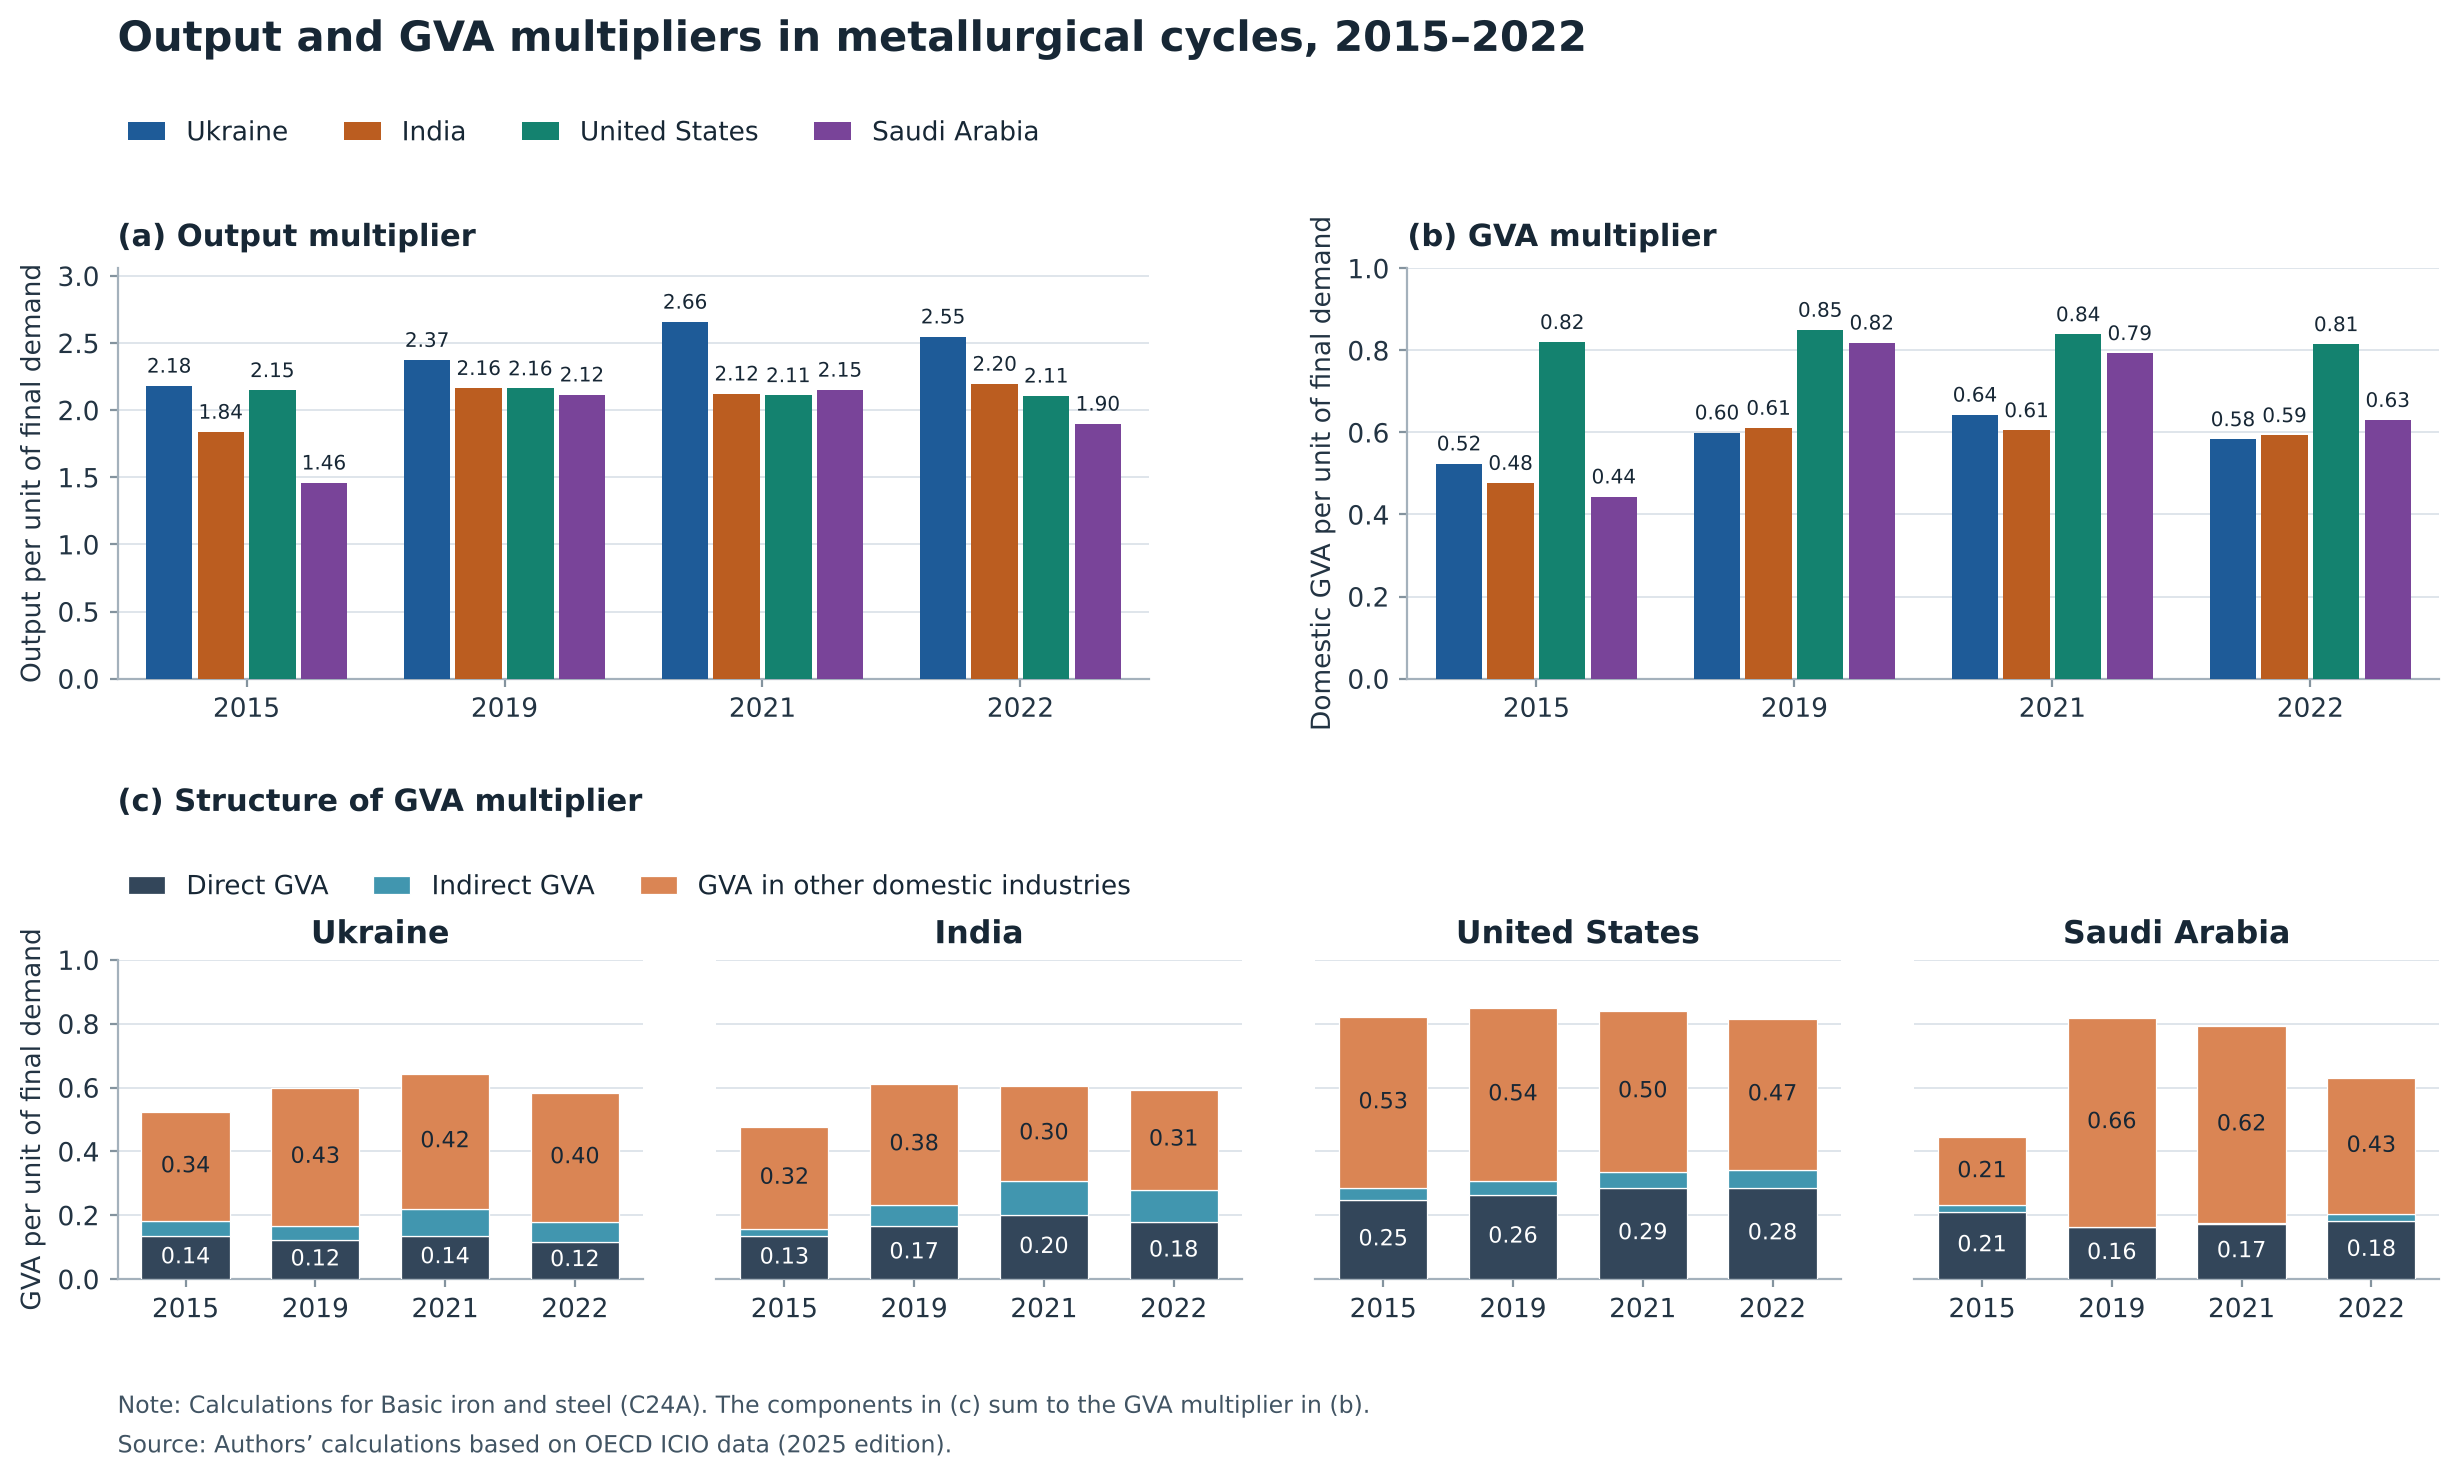

In [13]:
# Figure 5. Output multiplier, GVA multiplier and structure of the GVA multiplier for C24A.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.ticker import MultipleLocator

figure_5_shell = get_ipython()
figure_5_inline = figure_5_shell is not None and getattr(figure_5_shell, "kernel", None) is not None
if figure_5_inline:
    figure_5_shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

figure_5_country_colors = {
    "UKR": "#1E5B98", "IND": "#BB5D20", "USA": "#14826F", "SAU": "#794499",
}
figure_5_gva_styles = {
    "va_direct": ("Direct GVA", "#33465A"),
    "va_own_feedback": ("Indirect GVA", "#4196AF"),
    "va_other_domestic": ("GVA in other domestic industries", "#DA8554"),
}
figure_5_segment_label_colors = {
    "va_direct": "white", "va_other_domestic": "#172735",
}

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 9.5,
                     "axes.labelcolor": "#233443", "text.color": "#172735",
                     "xtick.color": "#233443", "ytick.color": "#233443",
                     "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}):
    figure_5 = plt.figure(figsize=(13.0, 7.6), facecolor="white")
    top_grid = figure_5.add_gridspec(1, 2, left=.087, right=.98, bottom=.54, top=.81, wspace=.25)
    lower_grid = figure_5.add_gridspec(1, 4, left=.087, right=.98, bottom=.145, top=.355, wspace=.14)
    year_positions = np.arange(len(YEARS))
    group_bar_step = .8 / len(COUNTRIES)
    country_offsets = (np.arange(len(COUNTRIES)) - (len(COUNTRIES) - 1) / 2) * group_bar_step
    top_axes = []
    panels = [
        (figure_5a_table, "output_multiplier", "(a) Output multiplier", "Output per unit of final demand", .5),
        (figure_5b_table, "va_total_domestic", "(b) GVA multiplier", "Domestic GVA per unit of final demand", .2),
    ]
    for index, (frame, column, title, unit, interval) in enumerate(panels):
        ax = figure_5.add_subplot(top_grid[0, index])
        top_axes.append(ax)
        series = frame.set_index(["country", "year"])[column]
        for country, offset in zip(COUNTRIES, country_offsets):
            values = series.loc[country].reindex(YEARS).to_numpy()
            bars = ax.bar(year_positions + offset, values, width=group_bar_step * .9,
                          color=figure_5_country_colors[country], label=COUNTRY_NAMES[country], zorder=3)
            ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=7.2)
        ax.set_ylim(0, series.max() * 1.15)
        ax.set_title(title, loc="left", fontweight="semibold", fontsize=11, pad=8)
        ax.set_ylabel(unit)
        ax.set_xticks(year_positions, [str(year) for year in YEARS])
        ax.set_xlim(-.5, len(YEARS) - .5)
        ax.yaxis.set_major_locator(MultipleLocator(interval))

    gva_axes = []
    gva_by_case = figure_5b_table.set_index(["country", "year"])
    for index, country in enumerate(COUNTRIES):
        ax = figure_5.add_subplot(lower_grid[0, index], sharey=gva_axes[0] if gva_axes else None)
        gva_axes.append(ax)
        series = gva_by_case.loc[country].reindex(YEARS)
        positive = np.zeros(len(YEARS))
        negative = np.zeros(len(YEARS))
        for metric, (label, color) in figure_5_gva_styles.items():
            values = series[metric].to_numpy()
            base = np.where(values >= 0, positive, negative)
            bars = ax.bar(year_positions, values, bottom=base, width=.68, color=color,
                          edgecolor="white", linewidth=.45, label=label, zorder=3)
            if metric in figure_5_segment_label_colors:
                ax.bar_label(bars, fmt="%.2f", label_type="center", fontsize=8,
                             color=figure_5_segment_label_colors[metric])
            positive += np.maximum(values, 0)
            negative += np.minimum(values, 0)
        ax.set_title(COUNTRY_NAMES[country], fontweight="semibold", pad=6)
        ax.set_xticks(year_positions, [str(year) for year in YEARS])
        if index:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.spines["left"].set_visible(False)
    gva_axes[0].set_ylabel("GVA per unit of final demand")
    gva_axes[0].yaxis.set_major_locator(MultipleLocator(.2))
    values = figure_5b_table[list(figure_5_gva_styles)]
    gva_limits = (
        min(0, 1.05 * values.clip(upper=0).sum(axis=1).min()),
        max(1, 1.05 * values.clip(lower=0).sum(axis=1).max()),
    )
    top_axes[1].set_ylim(gva_limits)
    gva_axes[0].set_ylim(gva_limits)

    for ax in (*top_axes, *gva_axes):
        ax.grid(axis="y", color="#DCE3E9", linewidth=.65)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E")
        for pos in ("left", "bottom"):
            ax.spines[pos].set_color("#A4B1BC")

    figure_5.text(.087, .953, "Output and GVA multipliers in metallurgical cycles, 2015–2022",
                  fontsize=15, fontweight="bold")
    figure_5.legend(*top_axes[0].get_legend_handles_labels(), ncol=4, frameon=False,
                    loc="upper left", bbox_to_anchor=(.082, .923), columnspacing=2.1, handlelength=1.4)
    figure_5.text(.087, .453, "(c) Structure of GVA multiplier",
                  fontsize=11, fontweight="semibold")
    figure_5.legend(*gva_axes[0].get_legend_handles_labels(), ncol=3, frameon=False,
                    loc="upper left", bbox_to_anchor=(.082, .427), columnspacing=1.7, handlelength=1.4)
    figure_5.text(.087, .057, "Note: Calculations for Basic iron and steel (C24A). The components in (c) sum to the GVA multiplier in (b).",
                  fontsize=8.5, color="#415463")
    figure_5.text(.087, .031, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
                  fontsize=8.5, color="#415463")

    figure_5_png = OUTPUT_DIR / "Figure_5_Output_and_GVA_Multipliers.png"
    figure_5_pdf = OUTPUT_DIR / "Figure_5_Output_and_GVA_Multipliers.pdf"
    figure_5.savefig(figure_5_png, dpi=400, facecolor="white")
    figure_5.savefig(figure_5_pdf, facecolor="white")
    if figure_5_inline:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_5.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_5)

In [14]:
# Appendix B. Calculate own and other domestic output requirements for all six focal industries.
b2_component_sectors = {
    "raw_materials": ("COAL", "ORES", "METAL"),
    "energy": ("OILGAS", "COKE", "ELEC"),
    "logistics": ("TRANSP", "WAREH"),
    "services_and_other_industries": ("FABMET", "WASTE", "CONSTR", "TRADE", "OTHERS"),
}
b2_component_names = {
    "raw_materials": "Raw materials",
    "energy": "Energy",
    "logistics": "Logistics",
    "services_and_other_industries": "Services and other industries",
}
b2_sector_component = pd.Series({
    sector: component for component, members in b2_component_sectors.items() for sector in members
})
assert set(b2_sector_component.index) == set(sectors)
assert sum(map(len, b2_component_sectors.values())) == len(sectors)

b_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
b_focal_cases = pd.MultiIndex.from_product(
    [COUNTRIES, YEARS, figure_4_sectors], names=["country", "year", "sector"],
)
b_rows = []
for country, year in b_cases:
    _, _, leontief = models[country, year, "full_available"]
    for sector in leontief.columns.intersection(figure_4_sectors):
        requirements_j = leontief[sector]
        own = float(requirements_j.loc[sector])
        external = requirements_j.drop(sector)
        components = (
            external.groupby(b2_sector_component).sum().reindex(b2_component_names, fill_value=0.0)
        )
        total_output = float(requirements_j.sum())
        external_total = float(external.sum())
        np.testing.assert_allclose(
            [components.sum(), total_output - own], external_total, rtol=0, atol=1e-10,
        )
        b_rows.append({
            "country": country, "year": year, "sector": sector,
            "output_multiplier": total_output,
            "leontief_diagonal": own,
            "external_dependence": external_total,
            **components.to_dict(),
        })

b_results = pd.DataFrame(b_rows).set_index(["country", "year", "sector"])
b_meta_columns = ["country", "country_name", "year", "sector", "sector_name",
                  "oecd_icio_code", "scope", "gross_output", "status"]
b_meta = figure_4_table.set_index(["country", "year", "sector"])[
    ["country_name", "sector_name", "oecd_icio_code", "gross_output", "status"]
].reindex(b_focal_cases)
b_meta["scope"] = "full_available"
b_results = b_meta.join(b_results, validate="one_to_one").reset_index()
b_active = b_results["gross_output"].gt(0)
b_metrics = ["output_multiplier", "leontief_diagonal", "external_dependence", *b2_component_names]
assert b_results.loc[b_active, b_metrics].notna().all().all()
assert b_results.loc[~b_active, b_metrics].isna().all().all()

table_b1 = b_results[b_meta_columns + ["leontief_diagonal"]].copy()
table_b2 = b_results[b_meta_columns + b_metrics].copy()
figure_6_table = table_b2.loc[table_b2["sector"].eq(FOCUS)].copy()
figure_6_table = figure_6_table.set_index(["country", "year"]).loc[b_cases]

# Match Figure 6 to the independently assembled output multiplier table for C24A.
b_crosscheck = table_a1.set_index(["country", "year"]).loc[b_cases]
np.testing.assert_allclose(
    figure_6_table[["output_multiplier", "leontief_diagonal", "external_dependence"]],
    b_crosscheck[["output_multiplier", "own_sector_requirement", "other_domestic_sector_requirement"]],
    rtol=0, atol=1e-10,
)

figure_6_exports = {
    "Table_B1_Leontief_Diagonals": table_b1,
    "Table_B2_External_Dependence": table_b2,
}
for name, frame in figure_6_exports.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

b1_preview = (
    table_b1.pivot(index="sector", columns=["country", "year"], values="leontief_diagonal")
    .reindex(index=list(figure_4_sectors), columns=b_cases)
    .rename(index=figure_4_sectors, columns=COUNTRY_NAMES, level=0)
)
b2_preview = (
    table_b2[["sector", "country", "year", "external_dependence", *b2_component_names]]
    .rename(columns={"external_dependence": "External dependence", **b2_component_names})
    .melt(id_vars=["sector", "country", "year"], var_name="Component")
    .pivot(index=["sector", "Component"], columns=["country", "year"], values="value")
    .reindex(pd.MultiIndex.from_product(
        [figure_4_sectors, ["External dependence", *b2_component_names.values()]],
        names=["sector", "Component"],
    )).reindex(columns=b_cases)
    .rename(index=figure_4_sectors, columns=COUNTRY_NAMES, level=0)
)
display(Markdown("**Table B1. Diagonal elements of the Leontief inverse by focal industry**"))
display(b1_preview.round(3).astype(object).where(b1_preview.notna(), "—"))
display(Markdown("**Table B2. External dependence and its components by focal industry**"))
display(b2_preview.round(3).astype(object).where(b2_preview.notna(), "—"))

**Table B1. Diagonal elements of the Leontief inverse by focal industry**

country                             Ukraine                       India  \
year                                   2015   2019   2021   2022   2015   
sector                                                                    
Coal mining                           1.182  1.156  1.293  1.361  1.003   
Oil and gas extraction                1.025  1.048  1.128   1.14  1.006   
Metal ore mining                      1.001  1.002  1.005   1.01  1.014   
Coke and refined petroleum products   1.022  1.026  1.026  1.021  1.031   
Basic iron and steel                  1.341  1.357  1.612  1.521  1.176   
Fabricated metal products             1.057  1.077  1.128  1.085  1.049   

country                                                  United States         \
year                                  2019   2021   2022          2015   2019   
sector                                                                          
Coal mining                          1.002  1.036  1.037         1.058  1.035   
Oil and gas extraction               1.008  1.005  1.006         1.074  1.079   
Metal ore mining                     1.021  1.087  1.081         1.071  1.057   
Coke and refined petroleum products  1.041  1.082  1.056          1.03  1.031   
Basic iron and steel                 1.403  1.536  1.577         1.158  1.157   
Fabricated metal products            1.113  1.073  1.071          1.09   1.09   

country                                           Saudi Arabia                \
year                                  2021   2022         2015   2019   2021   
sector                                                                         
Coal mining                          1.022  1.011            —      —      —   
Oil and gas extraction               1.125  1.069        1.008  1.019  1.036   
Metal ore mining                     1.121  1.024        1.017  1.001  1.001   
Coke and refined petroleum products  1.031  1.073        1.044  1.078  1.141   
Basic iron and steel                 1.176  1.197        1.098  1.007  1.007   
Fabricated metal products             1.08  1.118        1.009  1.021   1.02   

country                                     
year                                  2022  
sector                                      
Coal mining                              —  
Oil and gas extraction               1.024  
Metal ore mining                     1.004  
Coke and refined petroleum products  1.117  
Basic iron and steel                 1.119  
Fabricated metal products            1.031

**Table B2. External dependence and its components by focal industry**

country                                                           Ukraine  \
year                                                                 2015   
sector                              Component                               
Coal mining                         External dependence             0.769   
                                    Raw materials                   0.103   
                                    Energy                          0.095   
                                    Logistics                       0.123   
                                    Services and other industries   0.447   
Oil and gas extraction              External dependence              0.49   
                                    Raw materials                   0.097   
                                    Energy                          0.027   
                                    Logistics                       0.052   
                                    Services and other industries   0.313   
Metal ore mining                    External dependence             0.113   
                                    Raw materials                    0.02   
                                    Energy                          0.014   
                                    Logistics                       0.018   
                                    Services and other industries   0.062   
Coke and refined petroleum products External dependence             0.836   
                                    Raw materials                   0.106   
                                    Energy                           0.33   
                                    Logistics                         0.1   
                                    Services and other industries   0.301   
Basic iron and steel                External dependence             0.841   
                                    Raw materials                   0.155   
                                    Energy                          0.102   
                                    Logistics                       0.108   
                                    Services and other industries   0.476   
Fabricated metal products           External dependence             1.306   
                                    Raw materials                    0.69   
                                    Energy                          0.066   
                                    Logistics                         0.1   
                                    Services and other industries    0.45   

country                                                                   \
year                                                                2019   
sector                              Component                              
Coal mining                         External dependence            0.697   
                                    Raw materials                  0.076   
                                    Energy                         0.093   
                                    Logistics                      0.077   
                                    Services and other industries   0.45   
Oil and gas extraction              External dependence             0.48   
                                    Raw materials                  0.118   
                                    Energy                         0.022   
                                    Logistics                      0.046   
                                    Services and other industries  0.294   
Metal ore mining                    External dependence            0.139   
                                    Raw materials                  0.021   
                                    Energy                         0.017   
                                    Logistics                      0.026   
                                    Services and other industries  0.075   
Coke and refined petroleum products External dependence            0.924   
              

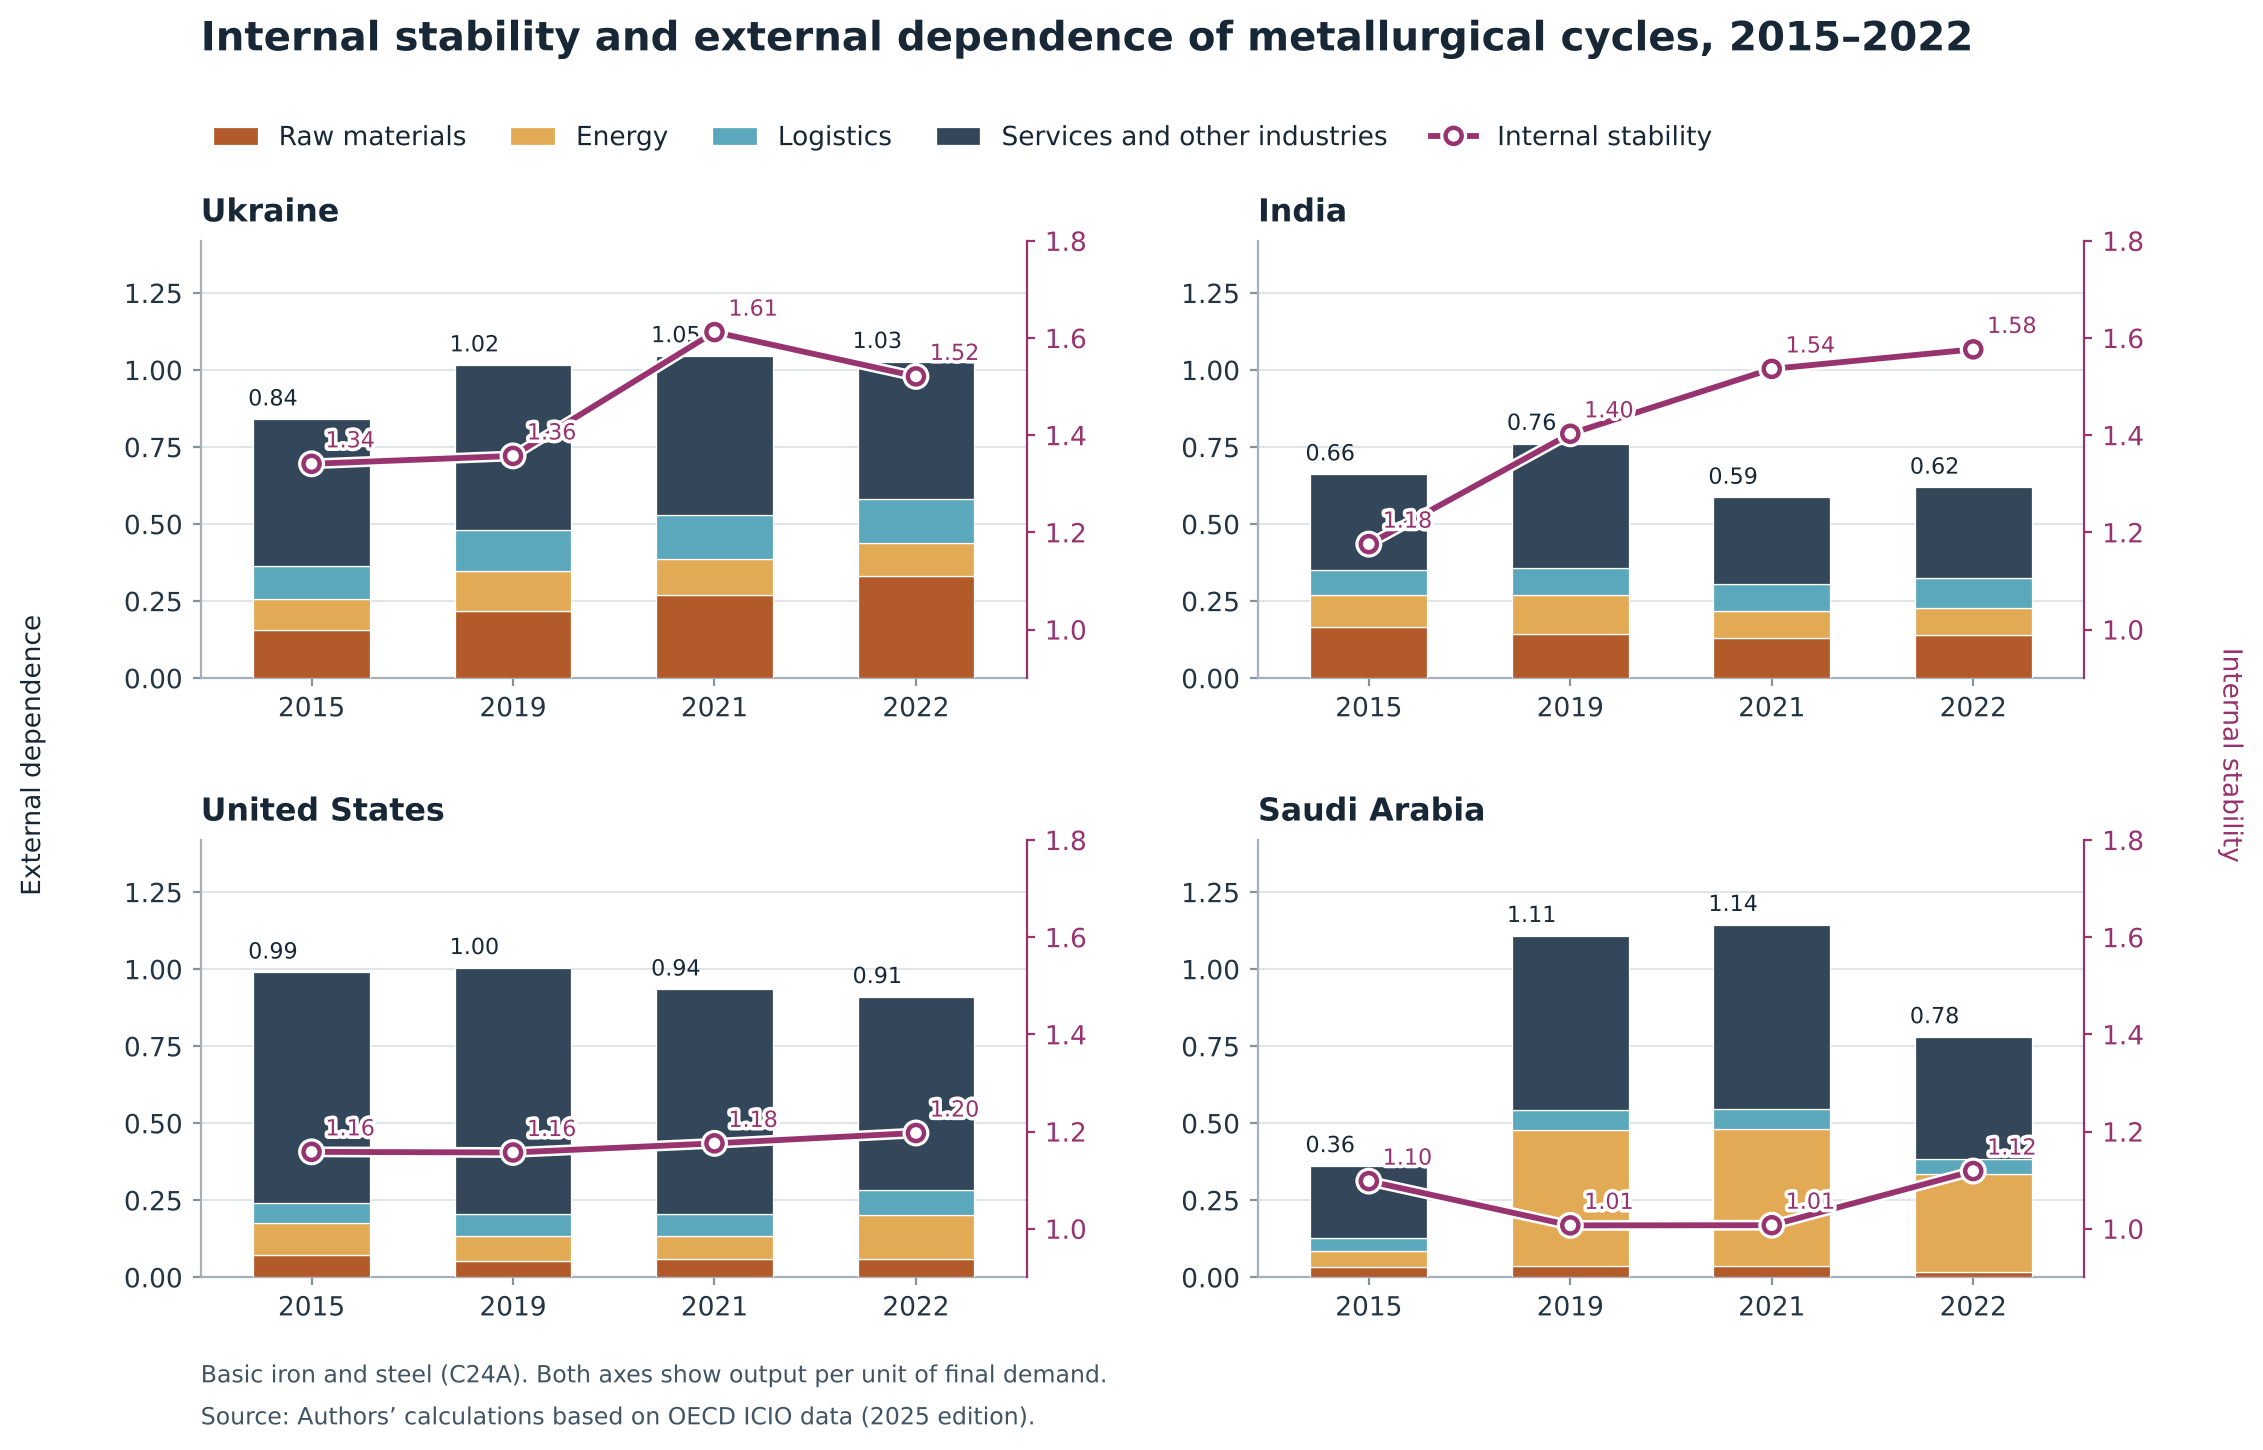

In [15]:
# Figure 6. Own and other domestic output requirements for basic iron and steel (C24A).
from matplotlib import patheffects

figure_6_shell = get_ipython()
figure_6_inline = figure_6_shell is not None and getattr(figure_6_shell, "kernel", None) is not None
if figure_6_inline:
    figure_6_shell.run_line_magic("matplotlib", "inline")

figure_6_component_colors = {
    "raw_materials": "#B35A2A",
    "energy": "#E3AA55",
    "logistics": "#5BA7BB",
    "services_and_other_industries": "#33465A",
}
figure_6_year_positions = np.arange(len(YEARS))
figure_6_year_labels = [str(year) for year in YEARS]

figure_6_stability_color = "#973470"
figure_6_left_limit = (0, figure_6_table["external_dependence"].max() * 1.24)
figure_6_right_limit = (.9, np.ceil((figure_6_table["leontief_diagonal"].max() + .08) / .2) * .2)

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 9.5,
                     "axes.labelcolor": "#233443", "text.color": "#172735",
                     "xtick.color": "#233443", "ytick.color": "#233443",
                     "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}):
    figure_6 = plt.figure(figsize=(11.8, 7.5), facecolor="white")
    grid = figure_6.add_gridspec(2, 2, left=.102, right=.9, bottom=.132, top=.823,
                                wspace=.28, hspace=.37)
    dependence_axes = []
    stability_axes = []
    for panel, country in zip(grid, COUNTRIES):
        ax = figure_6.add_subplot(panel)
        stability_ax = ax.twinx()
        dependence_axes.append(ax)
        stability_axes.append(stability_ax)
        case = figure_6_table.loc[country].reindex(YEARS)

        base = np.zeros(len(YEARS))
        for component, label in b2_component_names.items():
            values = case[component].to_numpy()
            ax.bar(figure_6_year_positions, values, bottom=base, width=.58,
                   color=figure_6_component_colors[component], edgecolor="white",
                   linewidth=.45, label=label, zorder=3)
            base += values

        stability_line, = stability_ax.plot(
            figure_6_year_positions, case["leontief_diagonal"], color=figure_6_stability_color,
            marker="o", markerfacecolor="white", markersize=5.8, markeredgewidth=1.6,
            linewidth=2.1, label="Internal stability", zorder=5,
        )
        stability_line.set_path_effects([patheffects.withStroke(linewidth=3.9, foreground="white")])
        for position, external, stability in zip(
            figure_6_year_positions, case["external_dependence"], case["leontief_diagonal"]
        ):
            ax.annotate(f"{external:.2f}", (position, external),
                        xytext=(-5, 3), textcoords="offset points", ha="right", va="bottom",
                        fontsize=8, zorder=6)
            stability_ax.annotate(f"{stability:.2f}", (position, stability),
                                  xytext=(5, 4), textcoords="offset points", ha="left", va="bottom",
                                  fontsize=8, color=figure_6_stability_color,
                                  path_effects=[patheffects.withStroke(linewidth=2.6, foreground="white")],
                                  zorder=6)

        ax.set_title(COUNTRY_NAMES[country], loc="left", fontweight="semibold", pad=7)
        ax.set_xticks(figure_6_year_positions, figure_6_year_labels)
        ax.set_xlim(-.55, len(YEARS) - .45)
        ax.set_ylim(figure_6_left_limit)
        ax.yaxis.set_major_locator(MultipleLocator(.25))
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#DCE3E9", linewidth=.65)
        ax.tick_params(length=3, color="#84939E")
        ax.spines["left"].set_color("#A4B1BC")
        ax.spines["bottom"].set_color("#A4B1BC")

        stability_ax.set_ylim(figure_6_right_limit)
        stability_ax.yaxis.set_major_locator(MultipleLocator(.2))
        stability_ax.tick_params(axis="y", colors=figure_6_stability_color, length=3)
        stability_ax.spines["right"].set_visible(True)
        stability_ax.spines["right"].set_color(figure_6_stability_color)
        stability_ax.spines["left"].set_visible(False)
        stability_ax.spines["bottom"].set_visible(False)

    figure_6.text(.102, .95, "Internal stability and external dependence of metallurgical cycles, 2015–2022",
                  fontsize=14.5, fontweight="bold")
    handles, labels = dependence_axes[0].get_legend_handles_labels()
    line_handles, line_labels = stability_axes[0].get_legend_handles_labels()
    figure_6.legend(handles + line_handles, labels + line_labels, ncol=5, frameon=False,
                    loc="upper left", bbox_to_anchor=(.097, .916), columnspacing=1.65, handlelength=1.7)
    figure_6.text(.031, .48, "External dependence", rotation=90, ha="center", va="center")
    figure_6.text(.962, .48, "Internal stability", rotation=270, ha="center", va="center",
                  color=figure_6_stability_color)
    figure_6.text(.102, .062, "Basic iron and steel (C24A). Both axes show output per unit of final demand.",
                  fontsize=8.5, color="#415463")
    figure_6.text(.102, .034, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
                  fontsize=8.5, color="#415463")

    figure_6_png = OUTPUT_DIR / "Figure_6_Internal_Stability_and_External_Dependence.png"
    figure_6_pdf = OUTPUT_DIR / "Figure_6_Internal_Stability_and_External_Dependence.pdf"
    figure_6.savefig(figure_6_png, dpi=400, facecolor="white")
    figure_6.savefig(figure_6_pdf, facecolor="white")
    if figure_6_inline:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_6.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_6)

In [16]:
# Save Tables A1, A2, B1 and B2 as CSV files.
publication_tables = {**figure_5_exports, **figure_6_exports}

for name, table in publication_tables.items():
    csv_path = OUTPUT_DIR / f"{name}.csv"
    table.to_csv(csv_path, index=False, encoding="utf-8-sig")
    print(f"Saved {csv_path} ({len(table)} rows)")


Saved /home/claude/test/results/Table_A1_Output_Multipliers.csv (16 rows)
Saved /home/claude/test/results/Table_A2_GVA_Multipliers.csv (96 rows)
Saved /home/claude/test/results/Table_B1_Leontief_Diagonals.csv (96 rows)
Saved /home/claude/test/results/Table_B2_External_Dependence.csv (96 rows)


In [17]:
# Apply the seven economic configurations to the full-model C24A observations.
classification_keys = ["country", "year"]
classification_resource_sectors = ["COAL", "OILGAS", "ORES", "COKE"]
classification_cutoffs = {"R": 0.50, "D": 0.75, "X": 0.50, "E": 0.10}

classification_resource_gva = (
    va_by_supplier.loc[
        va_by_supplier["scope"].eq("full_available")
        & va_by_supplier["supplier_sector"].isin(classification_resource_sectors)
        & va_by_supplier["supplier_sector"].ne(FOCUS)
    ]
    .groupby(classification_keys)["va_contribution"].sum().rename("E")
    .reset_index()
)

classification_c24a = (
    va_steel.loc[va_steel["scope"].eq("full_available"),
                 classification_keys + ["va_direct", "va_own_feedback", "va_total_domestic"]]
    .merge(direct[classification_keys + ["reported_export_share"]],
           on=classification_keys, validate="one_to_one")
    .merge(classification_resource_gva, on=classification_keys, validate="one_to_one")
    .set_index(classification_keys)
    .reindex(pd.MultiIndex.from_product([COUNTRIES, YEARS], names=classification_keys))
    .rename(columns={"va_total_domestic": "D", "reported_export_share": "X"})
)
classification_c24a["R"] = (
    classification_c24a["va_direct"] + classification_c24a["va_own_feedback"]
) / classification_c24a["D"]
assert np.isfinite(classification_c24a[["R", "D", "X", "E"]]).all().all()
assert classification_c24a["D"].gt(0).all()

high_r, high_d, high_x, high_e = (
    classification_c24a[k].ge(cutoff) for k, cutoff in classification_cutoffs.items()
)
classification_rules = pd.DataFrame({
    "Income multiplier": ~high_r & high_d & ~high_e,
    "Income generator": high_r & high_d & ~high_x,
    "Resource multiplier": ~high_r & high_d & high_e,
    "Isolated link": high_r & ~high_d & ~high_x,
    "Dispersed link": ~high_r & ~high_d & ~high_e,
    "Rent buffer": high_r & high_x,
    "Cost transmitter": ~high_r & ~high_d & high_e,
})
assert classification_rules.sum(axis=1).eq(1).all()
classification_c24a["configuration"] = classification_rules.idxmax(axis=1)
classification_c24a = classification_c24a[["R", "D", "X", "E", "configuration"]]

classification_csv = OUTPUT_DIR / "figure_7_c24a_classification.csv"
classification_c24a.to_csv(classification_csv, encoding="utf-8-sig")
display(classification_c24a.round(3))

R      D      X      E        configuration
country year                                                 
UKR     2015  0.346  0.524  0.392  0.079       Dispersed link
        2019  0.275  0.600  0.233  0.129     Cost transmitter
        2021  0.341  0.643  0.369  0.119     Cost transmitter
        2022  0.306  0.583  0.349  0.143     Cost transmitter
IND     2015  0.329  0.477  0.109  0.104     Cost transmitter
        2019  0.380  0.611  0.078  0.092       Dispersed link
        2021  0.507  0.605  0.102  0.081        Isolated link
        2022  0.472  0.593  0.079  0.082       Dispersed link
USA     2015  0.349  0.820  0.101  0.049    Income multiplier
        2019  0.360  0.850  0.074  0.035    Income multiplier
        2021  0.401  0.839  0.086  0.040    Income multiplier
        2022  0.419  0.815  0.092  0.063    Income multiplier
SAU     2015  0.520  0.444  0.148  0.049        Isolated link
        2019  0.199  0.819  0.235  0.293  Resource multiplier
        2021  0.220  0.793  0.262  0.228  Resource multiplier
        2022  0.323  0.630  0.315  0.174     Cost transmitter

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


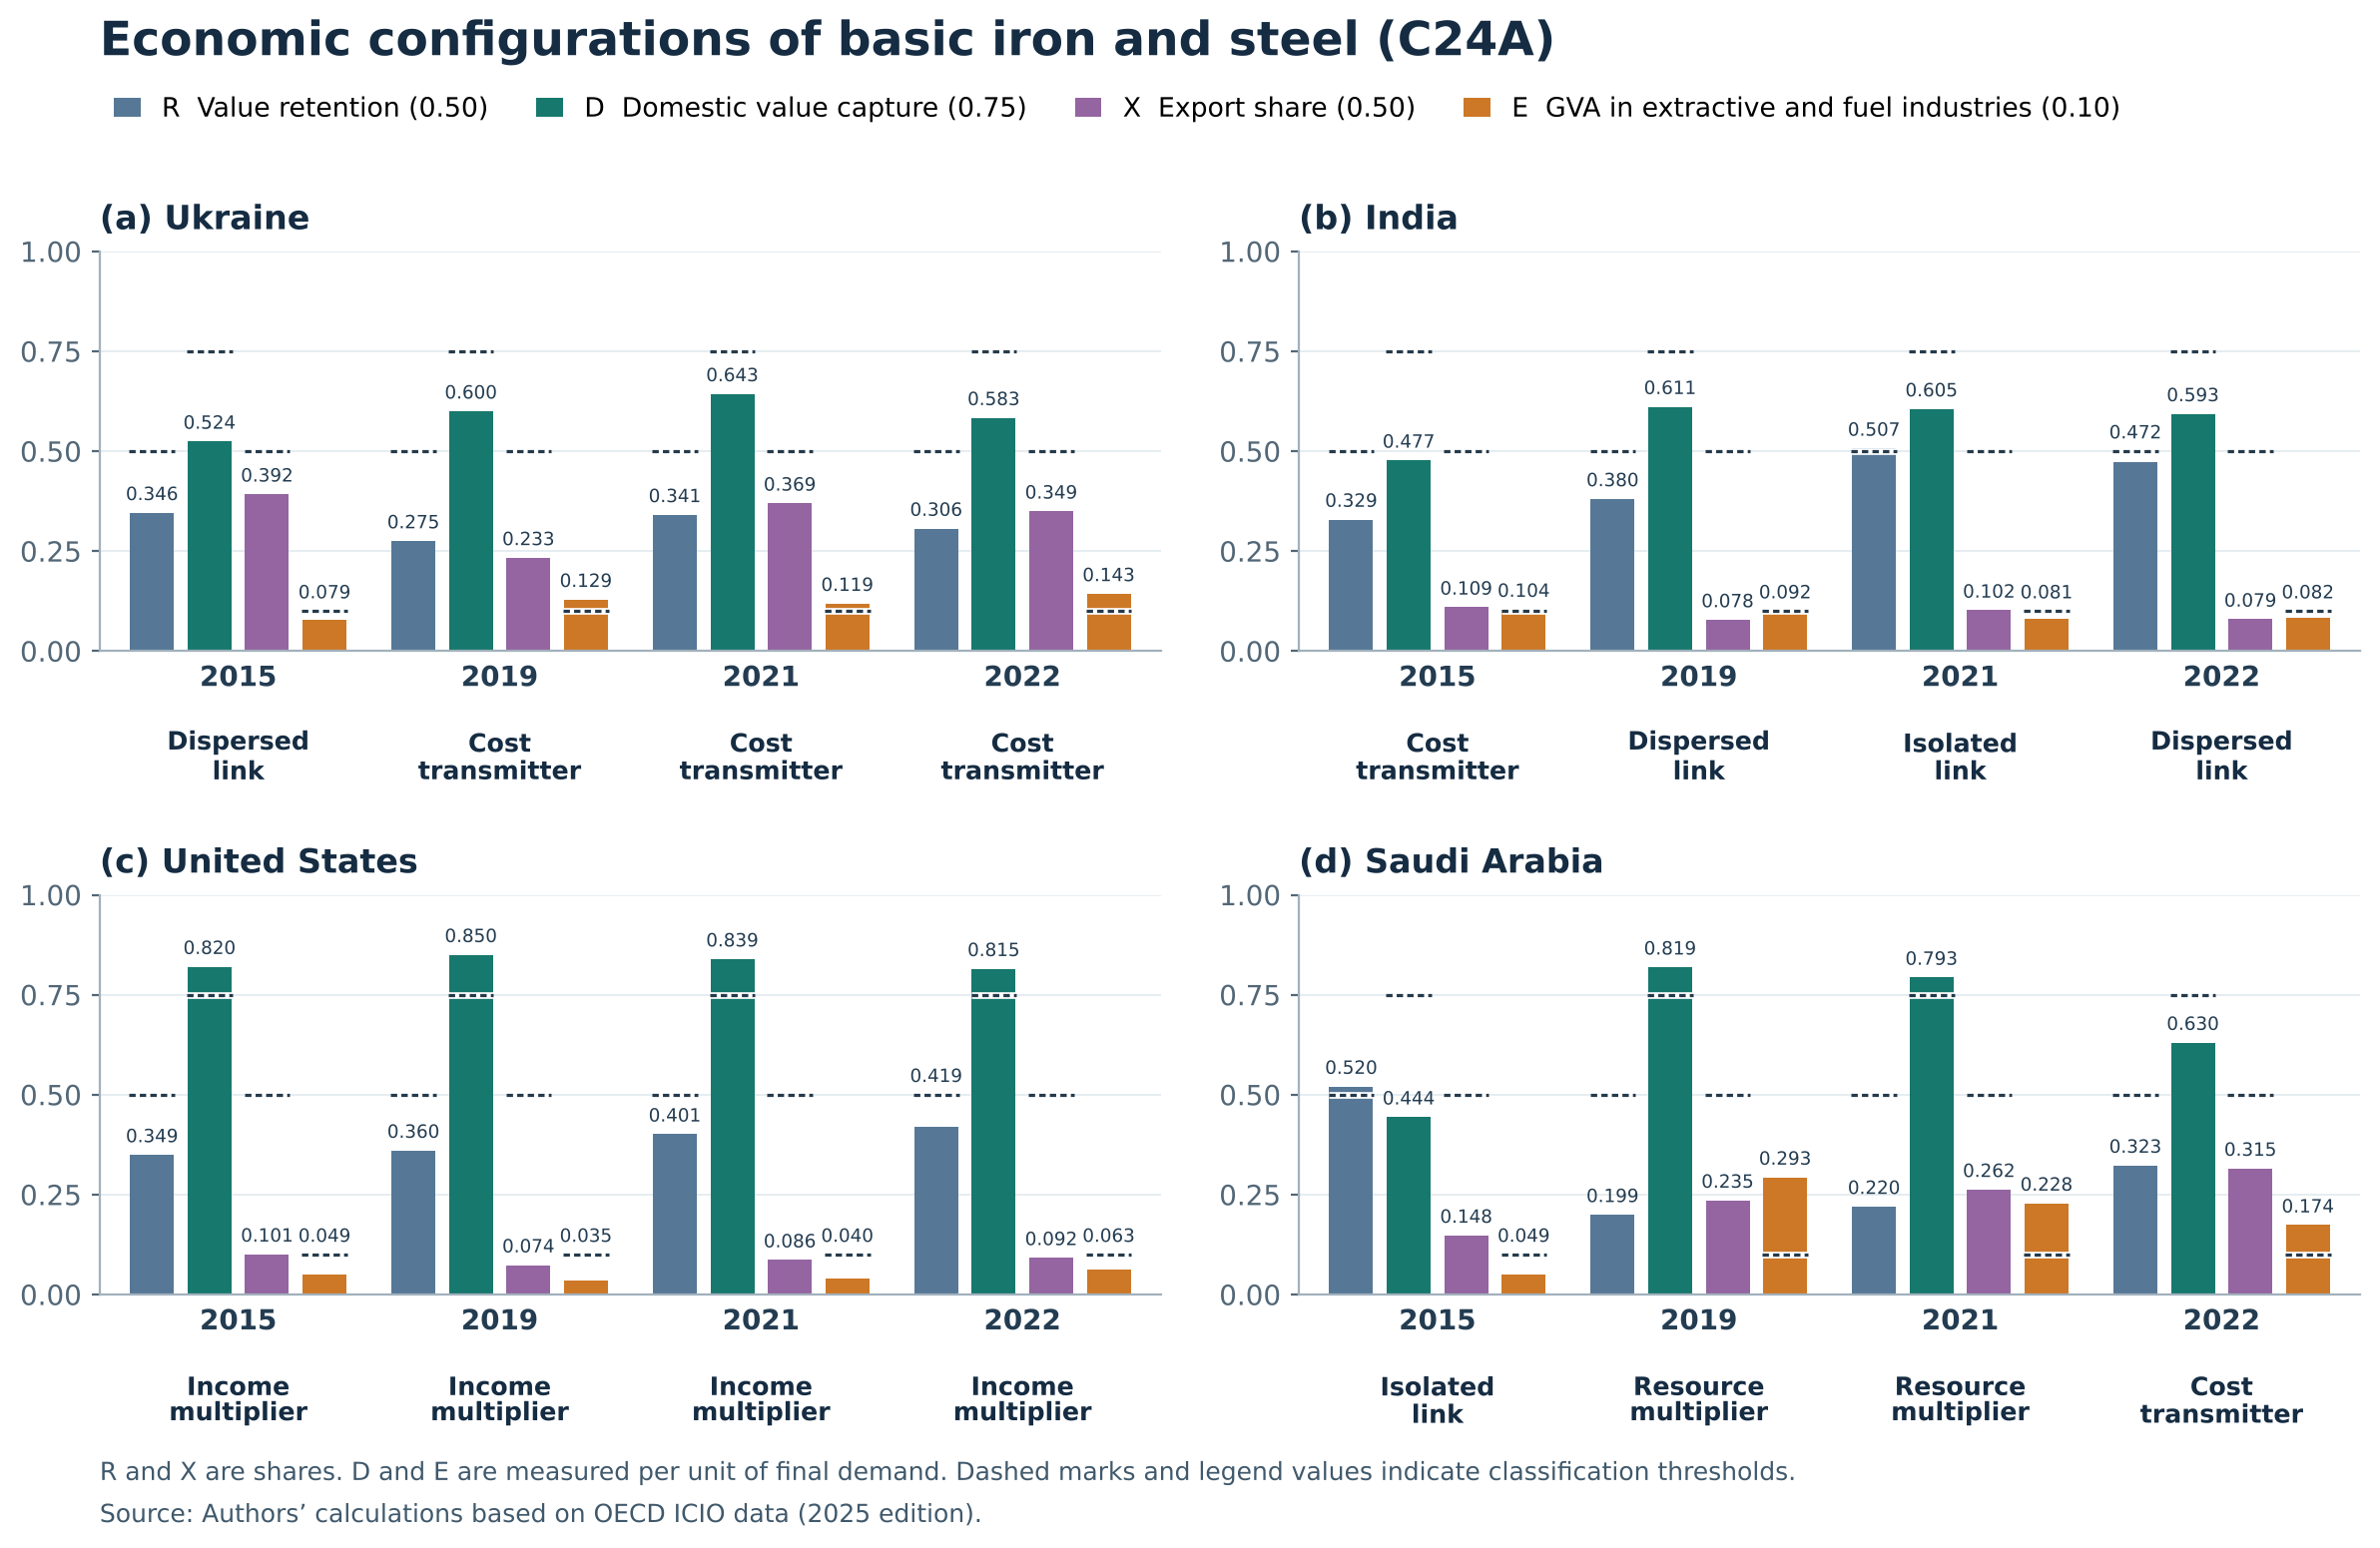

In [18]:
# Figure 7. Four country panels with the four indicators and the resulting C24A type.
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

indicator_style = {
    "R": ("Value retention", "#567896"),
    "D": ("Domestic value capture", "#17786D"),
    "X": ("Export share", "#9465A1"),
    "E": ("GVA in extractive and fuel industries", "#CC7827"),
}
bar_offsets = np.array([-0.33, -0.11, 0.11, 0.33])
year_positions = np.arange(len(YEARS))
country_panels = ("UKR", "IND", "USA", "SAU")

with plt.rc_context({
    "font.family": "DejaVu Sans", "font.size": 10, "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
}):
    figure_7, classification_axes = plt.subplots(
        2, 2, figsize=(12.4, 7.8), sharey=True, facecolor="white"
    )
    figure_7.subplots_adjust(left=.072, right=.985, top=.82, bottom=.15, wspace=.13, hspace=.61)
    figure_7.suptitle(
        "Economic configurations of basic iron and steel (C24A)",
        x=.072, y=.969, ha="left", fontsize=17, fontweight="bold", color="#152C42",
    )

    for panel_letter, country, ax in zip("abcd", country_panels, classification_axes.flat):
        profile = classification_c24a.loc[country].reindex(YEARS)
        ax.set_title(f"({panel_letter}) {COUNTRY_NAMES[country]}", loc="left", pad=8,
                     fontsize=12, fontweight="bold", color="#152C42")
        ax.set(xlim=(-.53, len(YEARS) - .47), ylim=(0, 1))
        ax.set_xticks(year_positions, YEARS, fontweight="semibold", color="#233C51")
        ax.tick_params(axis="x", length=0, pad=5)
        ax.tick_params(axis="y", length=3, colors="#526777", labelleft=True)
        ax.yaxis.set_major_locator(MultipleLocator(.25))
        ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
        ax.spines[["left", "bottom"]].set_color("#A2B1BC")
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#E6EDF1", linewidth=.7)

        for (indicator, (_, color)), offset in zip(indicator_style.items(), bar_offsets):
            x = year_positions + offset
            values = profile[indicator]
            cutoff = classification_cutoffs[indicator]
            bars = ax.bar(x, values, color=color, width=.168, zorder=2)
            ax.hlines([cutoff] * len(x), x - .087, x + .087, colors="white",
                      linewidth=2.4, zorder=3)
            ax.hlines([cutoff] * len(x), x - .087, x + .087, colors="#243A4B",
                      linewidth=1.15, linestyles=(0, (2, 1.3)), zorder=4)
            for bar, value in zip(bars, values):
                # Leave room for the threshold tick when a value falls just below it.
                label_y = cutoff if 0 < cutoff - value < .085 else value
                ax.annotate(
                    f"{value:.3f}", (bar.get_x() + bar.get_width() / 2, label_y),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                    color="#233C51", fontsize=6.6,
                )

        for position, configuration in zip(year_positions, profile["configuration"]):
            ax.text(
                position, -.195, configuration.replace(" ", "\n", 1),
                transform=ax.get_xaxis_transform(), ha="center", va="top",
                color="#152C42", fontsize=9.1, fontweight="semibold", linespacing=1.08,
            )

    indicator_handles = [
        Patch(facecolor=color, label=f"{key}  {label} ({classification_cutoffs[key]:.2f})")
        for key, (label, color) in indicator_style.items()
    ]
    figure_7.legend(
        handles=indicator_handles, loc="center left", bbox_to_anchor=(.068, .911),
        ncol=4, frameon=False, columnspacing=1.8, handlelength=1.0, fontsize=9.6,
    )
    figure_7.text(
        .072, .035,
        "R and X are shares. D and E are measured per unit of final demand. "
        "Dashed marks and legend values indicate classification thresholds.",
        color="#40596C", fontsize=9, ha="left", va="center",
    )
    figure_7.text(
        .072, .008, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
        color="#40596C", fontsize=9, ha="left", va="center",
    )
    figure_7_png = OUTPUT_DIR / "Figure_7_C24A_Classification.png"
    figure_7_pdf = OUTPUT_DIR / "Figure_7_C24A_Classification.pdf"
    figure_7.savefig(figure_7_png, dpi=350, bbox_inches="tight", facecolor="white")
    figure_7.savefig(figure_7_pdf, bbox_inches="tight", facecolor="white")
    if get_ipython() is not None and getattr(get_ipython(), "kernel", None) is not None:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_7.savefig(preview, format="png", dpi=110, bbox_inches="tight", facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_7)
